# Oral condition screening: binary classifier (normal vs issue)

**IT2226 AI Innovator and Deep Learning Project: Dental Health Awareness and Affordability in Singapore**

This notebook trains **stage 1** of the two-stage pipeline described in the oral dataset's README. It is an image classifier that answers one question: *does this mouth show any of the five screened conditions?* Images it flags go to **stage 2**, a YOLO detector that finds and names each condition (calculus, caries, hypodontia, mouth ulcer, tooth discoloration). Both stages share the same val/test images, so the whole pipeline can be scored end to end.

It compares a range of ImageNet-pretrained torchvision backbones under one data split and one training recipe, then picks one by a rule fixed before training.

> **Scope.** This is a *screening and education aid*. It does not diagnose, and its output must always come with a recommendation to see a dentist. "Normal" means none of the five screened conditions was seen. Gum disease is not a class, so a normal result never means "healthy gums".

### Data issues and how this notebook handles them

| Issue | What this notebook does | Section |
|---|---|---|
| **Source confound.** In val/test every issue image comes from `roboflow_oral` (all exactly 640×640) and every normal image from another source. A model that recognises the source scores well without looking at teeth | Two **cross-source check sets** are carved, by photo group, out of the non-Roboflow training sources, which contain both labels. One counts in model selection, the other is reported like test | 2, 3, 4, 6 |
| Imbalance: about 3 issue images per normal image; Roboflow is ~60% of training | The sampler draws both classes equally often and, within the issue class, gives Roboflow and the other sources half each. Macro-F1 / balanced accuracy are the headline metrics | 4 |
| Roboflow augmentations and re-uploads: many files of one photo | The dataset keeps every copy of a photo in one split (`group`). The sampler weights by photo, not file, and confidence intervals resample whole photo groups | 3, 4, 6 |
| Some labels come from Qwen, not people (train boxes outside Roboflow; most Normal images in val/test) | Test is also reported on person-labelled images only, and per source | 6 |
| Image quality, lighting and resolution differ by source | Every image is cached at ≤384 px; strong photometric + blur/JPEG augmentation; a "phone-quality" val copy in model selection; robustness test | 1, 4, 6 |
| Images are not from Singapore patients; no gum disease class | Cannot be fixed with this data; documented | 9 |

### Data

`data/raw/oral_dataset/`, built by `qwen_clean_and_label.ipynb` (sections 6-8): unzip `oral_dataset.zip` there. The notebook finds `labels.csv` anywhere under that folder (or in `$ORAL_DATASET_DIR`) and reads, per image: `split`, `has_issue` (the target), `dataset` (the source), `label_by`, `group` (photo group) and the five 0/1 condition columns (analysis only). The YOLO label files are not used here.

## 0. Setup

In [37]:
# Install the notebook's dependencies into THIS kernel's Python environment.
# Safe to re-run: only missing packages are installed. Restart the kernel afterwards if anything was installed.
import importlib.util, subprocess, sys

PACKAGES = {  # import name -> pip package
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib", "PIL": "pillow", "cv2": "opencv-python", "yaml": "pyyaml",
    "tqdm": "tqdm", "IPython": "ipython",
}
# PyTorch comes from its own index so the GPU build is installed (plain `pip install torch` gives the CPU build on Windows).
# CUDA 12.8 wheels support RTX 50-series cards; use "https://download.pytorch.org/whl/cpu" on a machine without an NVIDIA GPU.
TORCH_INDEX = "https://download.pytorch.org/whl/cu128"


def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


installed = []
missing = [pkg for mod, pkg in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", " ".join(missing))
    pip_install(*missing); installed += missing
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    print("installing torch + torchvision from", TORCH_INDEX)
    pip_install("torch", "torchvision", "--index-url", TORCH_INDEX); installed += ["torch", "torchvision"]

import torch, torchvision
tv_version = tuple(int(x) for x in torchvision.__version__.split("+")[0].split(".")[:2])
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"CUDA available: {torch.cuda.is_available()}")
if tv_version < (0, 20):
    print("WARNING: torchvision >= 0.20 is needed (v2.JPEG augmentation). Upgrade with:\n"
          f"  {sys.executable} -m pip install -U torch torchvision --index-url {TORCH_INDEX}")
if not torch.cuda.is_available():
    print("NOTE: no GPU visible. The notebook still runs on CPU, but training will be very slow.")
if installed:
    print("Installed packages: restart the kernel, then run the notebook from the next cell.")

python 3.13.14 | torch 2.10.0+cu130 | torchvision 0.25.0+cu130 | CUDA available: True


In [38]:
import os, io, json, time, math, random, hashlib, warnings, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import cv2
from PIL import Image, ImageOps, ImageFilter, ImageEnhance

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision as tv
from torchvision.transforms import v2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, average_precision_score)
from tqdm import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def find_repo_root():
    # Look for shared/conditions.yaml, in order:
    #  1. upwards from $DLWIU_ROOT (manual override), the kernel's working directory and the notebook's own folder
    #     (VS Code exposes it as __vsc_ipynb_file__);
    #  2. the notebook's path re-rooted at this machine's home folder. On a remote Jupyter server VS Code sends the
    #     *client's* path (e.g. C:\Users\me\OneDrive\Documents\School\...), so we also try ~/Documents/School/...,
    #     ~/OneDrive/Documents/School/..., and every other tail of that path under the server's home;
    #  3. up to two levels below the kernel's working directory (e.g. C:\Jupyter\Deep-Learning-WIU).
    def search_up(start):
        for p in [start, *start.parents]:
            if (p / "shared" / "conditions.yaml").exists():
                return p.resolve()
        return None

    starts = []
    if os.environ.get("DLWIU_ROOT"):
        starts.append(Path(os.environ["DLWIU_ROOT"]))
    starts.append(Path.cwd())
    nb_dir = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else None
    if nb_dir is not None:
        starts.append(nb_dir)
    for s in starts:
        if (root := search_up(s)) is not None:
            return root
    if nb_dir is not None:
        parts = nb_dir.parts[1:]                       # drop the drive / anchor
        for base in [Path.home(), Path.home() / "OneDrive"]:
            for i in range(len(parts)):
                cand = base.joinpath(*parts[i:])
                if (root := search_up(cand)) is not None:      # cand need not exist (older clone)
                    return root
    for pattern in ["*/shared/conditions.yaml", "*/*/shared/conditions.yaml"]:
        hits = sorted(Path.cwd().glob(pattern))
        if hits:
            return hits[0].parents[1].resolve()
    raise FileNotFoundError(
        f"Could not find the Deep-Learning-WIU repo (looked upwards from {[str(s) for s in starts]}, under {Path.home()} and two levels "
        f"below {Path.cwd()}). If this kernel runs on a remote Jupyter server, the repo and data/raw/oral_dataset must "
        "exist on THAT machine. Clone it there, or point to it before this cell: "
        "os.environ['DLWIU_ROOT'] = r'C:\\path\\to\\Deep-Learning-WIU'")


ROOT = find_repo_root()
RAW = ROOT / "data" / "raw"
CACHE_DIR = ROOT / "data" / "interim" / "Daniel" / "classifier_cache_oral"   # resized copies of every image (gitignored)
PROC = ROOT / "data" / "processed" / "classifier" / "Daniel"  # image index cache (gitignored)
MANIFESTS = ROOT / "manifests" / "Daniel"                    # split CSV (committed: reproducible without data)
# binary/ subfolders keep this classifier apart from the earlier 6-class Kaggle model in weights/Daniel/best.pt,
# which the demo app and the prototype still load.
WEIGHTS = ROOT / "models" / "classifier" / "weights" / "Daniel" / "binary"   # checkpoints (gitignored)
RESULTS = ROOT / "models" / "classifier" / "results" / "Daniel" / "binary"   # metrics + figures for the report
FIGS = RESULTS / "figures"
RUNS_DIR = RESULTS / "runs"                                                  # per-run history + summary
for d in [CACHE_DIR, PROC, MANIFESTS, WEIGHTS, RESULTS, FIGS, RUNS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,
    cache_max_side=384,          # every image is stored at <=384 px so all sources share a resolution
    img_size=224,
    ablation_backbone="convnext_tiny",   # backbone for the recipe ablation (A baseline vs B full recipe)
    # Backbones trained with the full recipe in section 5 (all torchvision, ImageNet-pretrained).
    # More are registered in BACKBONES (section 4): add them here, or trim this list for a quicker run.
    sweep=["convnext_tiny", "efficientnet_b0", "efficientnet_v2_s", "resnet50", "densenet121",
           "mobilenet_v3_large", "swin_t"],
    epochs=15, patience=4,
    epoch_samples=12000,         # training images drawn per epoch (with the sampler), so every run gets the same steps
    batch_size=32, eval_batch_size=128,
    # Worker processes that decode and augment images in parallel (classifier_data.py). With 0, one CPU core does it
    # all and the GPU waits. Lower them if the PC runs out of RAM; each worker is a separate Python process.
    num_workers=8, eval_workers=6,
    weight_decay=0.05, warmup_epochs=1,  # the peak learning rate is set per backbone family (BACKBONES)
    xsrc_frac=0.125,             # each cross-source check set takes ~1/8 of the non-Roboflow training photo groups
    tie_margin=0.01,             # runs within this val score of the best count as tied -> fastest on CPU wins
    target_sensitivity=0.95,     # operating threshold: catch at least 95% of issue images on val AND xsrc_val
    # A run that already has a checkpoint (weights/Daniel/binary/exp_<name>.pt) is never retrained; its saved results
    # are reused. List run names here to retrain them anyway, e.g. ["B_resnet50"], or "all" to retrain everything.
    retrain=[],
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16


def seed_everything(seed=CFG["seed"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def rel(p):
    # Repo-relative POSIX path for manifests and checkpoints (absolute if outside the repo).
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return str(p)


seed_everything()
torch.backends.cudnn.benchmark = True
print("repo root:", ROOT)
print("torch", torch.__version__, "| torchvision", tv.__version__, "| device:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

repo root: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU
torch 2.10.0+cu130 | torchvision 0.25.0+cu130 | device: cuda NVIDIA GeForce RTX 5070 Ti


In [39]:
# Two classes. Index 1 ("issue") is the positive class: has_issue == 1 in labels.csv.
CLASSES = ["normal", "issue"]
DISPLAY = {"normal": "None of the 5 screened conditions seen", "issue": "Possible oral condition: see a dentist"}
NUM_CLASSES, ISSUE = len(CLASSES), 1
print(dict(enumerate(CLASSES)))

{0: 'normal', 1: 'issue'}


## 1. Load the oral dataset

`labels.csv` has one row per image. Each image is then read once and, in the same pass:
- EXIF-rotated, downsized to at most 384 px and cached as JPEG under `data/interim/Daniel/classifier_cache_oral/<md5>.jpg`. Training reads only this cache, so a 1,500 px clinical photo and a 640 px Roboflow export reach the model at the same resolution;
- measured: original size, mean brightness and sharpness (variance of the Laplacian).

The measurements are saved to `data/processed/classifier/Daniel/oral_dataset_index.csv`, so a re-run only processes new images. The first pass over ~38,000 images takes several minutes.

In [40]:
def find_dataset():
    # Folder holding labels.csv + data.yaml of the unzipped oral dataset; $ORAL_DATASET_DIR overrides the search.
    if os.environ.get("ORAL_DATASET_DIR"):
        cands = [Path(os.environ["ORAL_DATASET_DIR"]) / "labels.csv"]
    else:
        cands = sorted(RAW.glob("oral_dataset/**/labels.csv"), key=lambda p: len(p.parts))
    cands = [p for p in cands if p.exists() and (p.parent / "data.yaml").exists()]
    if not cands:
        zips = sorted(RAW.glob("oral_dataset/*.zip"))
        hint = f" Found {zips[0].name}: unzip it inside {zips[0].parent}." if zips else ""
        raise FileNotFoundError(f"No oral dataset (labels.csv + data.yaml) under {RAW / 'oral_dataset'}.{hint}")
    return cands[0].parent


DATA_DIR = find_dataset()
CONDITIONS = yaml.safe_load(open(DATA_DIR / "data.yaml"))["names"]   # the 5 YOLO classes, for analysis only

df = pd.read_csv(DATA_DIR / "labels.csv")
df["path"] = [str(DATA_DIR / p) for p in df.image]
df["y"] = df.has_issue.astype(int)
df["label"] = np.array(CLASSES)[df.y]
df["group"] = "g" + df.group.astype(str).str.zfill(5)
df["roboflow"] = df.dataset.eq("roboflow_oral")
assert df.md5.is_unique, "md5 must identify an image"
assert df.groupby("group").split.nunique().max() == 1, "a photo group straddles splits"

print("dataset:", DATA_DIR)
print(f"{len(df)} images | {df.group.nunique()} photo groups | conditions: {CONDITIONS}")
pd.crosstab(df.split, df.label, margins=True).loc[["train", "val", "test", "All"]]

dataset: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\raw\oral_dataset\oral_dataset
33843 images | 16640 photo groups | conditions: ['Calculus', 'Caries', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration']


label,issue,normal,All
split,,,
train,23265,4591,27856
val,2301,640,2941
test,2447,599,3046
All,28013,5830,33843


In [41]:
INDEX_CSV = PROC / "oral_dataset_index.csv"
INDEX_COLS = ["md5", "orig_w", "orig_h", "brightness", "sharpness", "ok"]


def load_rgb(src, max_side=None):
    # Open, honour EXIF orientation, convert to RGB and optionally downsize (fast JPEG draft decode).
    im = Image.open(src)
    if max_side and im.format == "JPEG":
        im.draft("RGB", (max_side, max_side))
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side), Image.LANCZOS)
    return im


def cache_path(md5):
    return CACHE_DIR / f"{md5}.jpg"


def index_images(df):
    # Caches each image at <= cache_max_side px and measures its original size, brightness and sharpness.
    # Results are keyed by md5 and saved; only images that are new (or whose cached copy is missing) are processed.
    old = pd.read_csv(INDEX_CSV) if INDEX_CSV.exists() else pd.DataFrame(columns=INDEX_COLS)
    done = set(old.md5[old.ok.astype(bool)])
    todo = df[[(m not in done) or not cache_path(m).exists() for m in df.md5]]
    recs = []
    for md5, p in tqdm(zip(todo.md5, todo.path), total=len(todo), desc="caching"):
        r = dict(md5=md5, orig_w=np.nan, orig_h=np.nan, brightness=np.nan, sharpness=np.nan, ok=False)
        try:
            with Image.open(p) as im0:
                w, h = im0.size
                if im0.getexif().get(0x0112, 1) in (5, 6, 7, 8):   # EXIF says rotated 90 degrees
                    w, h = h, w
            if not cache_path(md5).exists():
                load_rgb(p, CFG["cache_max_side"]).save(cache_path(md5), quality=95)
            gray = np.asarray(Image.open(cache_path(md5)).convert("L"))
            r.update(orig_w=w, orig_h=h, brightness=float(gray.mean()),
                     sharpness=float(cv2.Laplacian(gray, cv2.CV_64F).var()), ok=True)
        except Exception as e:  # unreadable / truncated file
            print("unreadable:", p, e)
        recs.append(r)
    if recs:
        new = pd.DataFrame(recs, columns=INDEX_COLS)
        old = pd.concat([old[~old.md5.isin(new.md5)], new], ignore_index=True)
        old.to_csv(INDEX_CSV, index=False)
    return df.merge(old, on="md5", how="left")


df = index_images(df)
bad = ~df.ok.fillna(False).astype(bool)
print(f"unreadable images dropped: {bad.sum()}")
df = df[~bad].reset_index(drop=True)
df["cache"] = [str(cache_path(m)) for m in df.md5]
df["megapixels"] = df.orig_w * df.orig_h / 1e6
df["aspect"] = df.orig_w / df.orig_h
df["stratum"] = df.dataset + " | " + df.label
print(f"{len(df)} images ready")

caching: 0it [00:00, ?it/s]

unreadable images dropped: 0
33843 images ready


## 2. Exploratory analysis: the source confound

For a binary classifier the first question is whether anything *other than the mouth* separates the two classes. In this dataset the **source** does.

split               test         train          val       
label              issue normal  issue normal issue normal
dataset                                                   
dentalai               0     92   1497    737     0     91
external_clean         0      6    325     50     0      6
kaggle_oral            0     60    754    120     0     59
mendeley_noncaries     0    435      0   3634     0    478
roboflow_oral       2447      0  18529      0  2301      0
zenodo                 0      6   2160     50     0      6

Issue images that contain each condition (an image counts once per condition it has):


,Calculus,Caries,Hypodontia,Mouth_Ulcer,Tooth_Discoloration
split,,,,,
train,3587,10749,2500,4698,7914
val,429,845,288,550,868
test,415,811,397,568,885


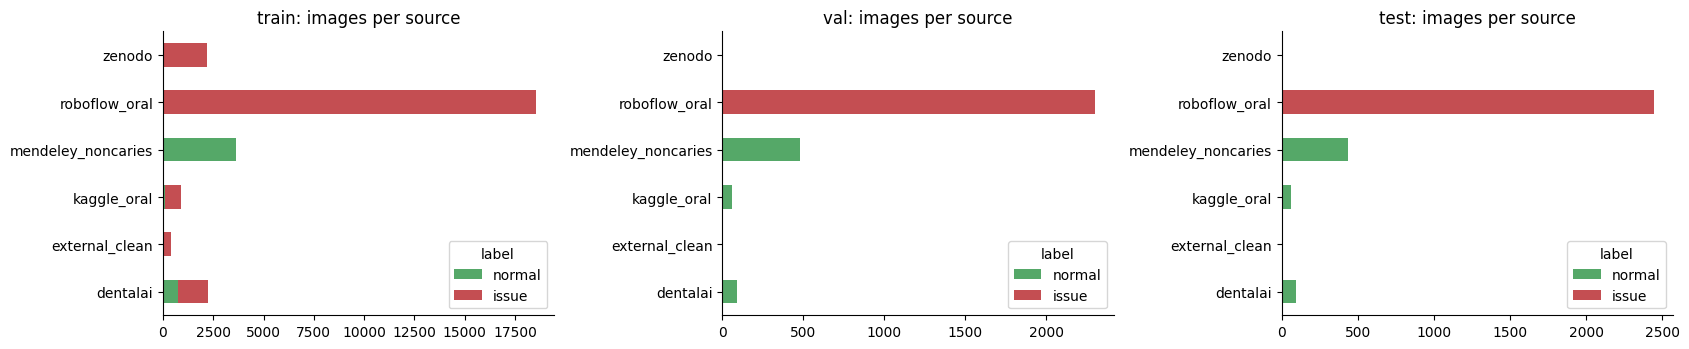

In [42]:
display(pd.crosstab(df.dataset, [df.split, df.label]))
print("Issue images that contain each condition (an image counts once per condition it has):")
display(df[df.y == 1].groupby("split")[CONDITIONS].sum().loc[["train", "val", "test"]])

fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
for a, s in zip(ax, ["train", "val", "test"]):
    d = df[df.split == s]
    pd.crosstab(d.dataset, d.label).reindex(columns=CLASSES, fill_value=0).plot.barh(
        ax=a, stacked=True, color=["#55A868", "#C44E52"])
    a.set_title(f"{s}: images per source"); a.set_ylabel("")
plt.tight_layout(); plt.savefig(FIGS / "eda_source_by_class.png", bbox_inches="tight"); plt.show()

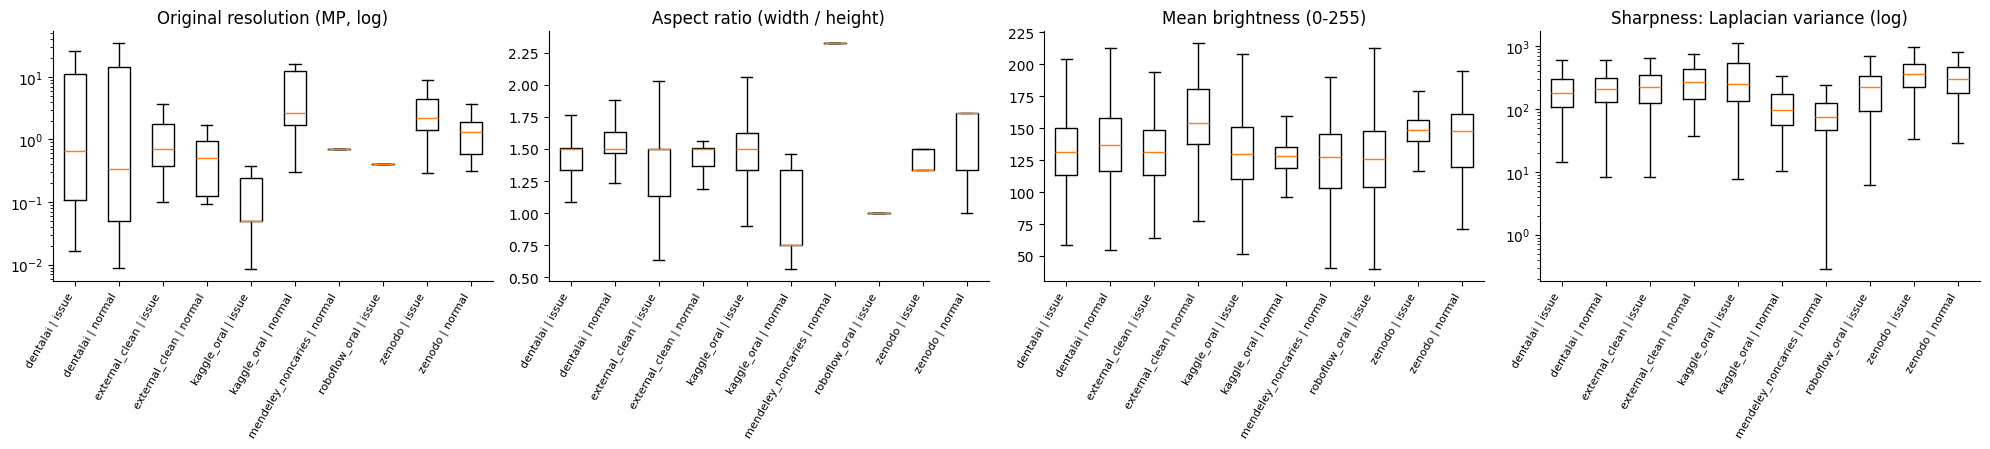

images  median_MP  share_640x640  median_brightness  median_sharpness
dataset            label                                                                        
dentalai           issue     1497       0.65            0.0             131.25            180.44
                   normal     920       0.34            0.0             136.57            204.52
external_clean     issue      325       0.70            0.0             131.24            220.93
                   normal      62       0.51            0.0             154.15            270.69
kaggle_oral        issue      754       0.05            0.0             129.63            253.20
                   normal     239       2.64            0.0             128.28             95.44
mendeley_noncaries normal    4547       0.70            0.0             127.18             75.73
roboflow_oral      issue    23277       0.41            1.0             126.12            222.11
zenodo             issue     2160       2.24            0.0             148.77            359.33
                   normal      62       1.30            0.0             147.66            297.28

In [43]:
order = sorted(df.stratum.unique())
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for a, col, title, log in [(ax[0], "megapixels", "Original resolution (MP, log)", True),
                           (ax[1], "aspect", "Aspect ratio (width / height)", False),
                           (ax[2], "brightness", "Mean brightness (0-255)", False),
                           (ax[3], "sharpness", "Sharpness: Laplacian variance (log)", True)]:
    a.boxplot([df.loc[df.stratum == s, col].dropna() for s in order], showfliers=False)
    a.set_xticks(range(1, len(order) + 1), order, rotation=60, ha="right", fontsize=8); a.set_title(title)
    if log: a.set_yscale("log")
plt.tight_layout(); plt.savefig(FIGS / "eda_quality_by_source.png", bbox_inches="tight"); plt.show()

(df.assign(square_640=df.orig_w.eq(640) & df.orig_h.eq(640))
   .groupby(["dataset", "label"])
   .agg(images=("md5", "size"), median_MP=("megapixels", "median"), share_640x640=("square_640", "mean"),
        median_brightness=("brightness", "median"), median_sharpness=("sharpness", "median"))
   .round(2))

**Reading the tables and plots**
- **In val and test, every issue image is from Roboflow and no normal image is.** Every Roboflow image is exactly 640×640 (Roboflow resized them on export), while the other sources keep their own cameras' resolutions and aspect ratios. A model can therefore reach a near-perfect val/test score by detecting "a Roboflow-looking image", and that score would say nothing about a patient's phone photo.
- Training has the same pattern for Roboflow, but four other sources (`dentalai`, `zenodo`, `kaggle_oral`, `external_clean`) contain **both** labels. Those make an honest check possible (section 3).
- Outside Roboflow, issue images are mostly **caries** (zenodo also has many discoloration images; `kaggle_oral` and `external_clean` are mixed). The cross-source check therefore mostly measures caries vs normal on other cameras, not all five conditions.

What helps: images are cached at ≤384 px and squashed to 224×224, random resized crops vary the aspect ratio, blur/JPEG augmentation hides compression differences, and the sampler shows the model non-Roboflow issue images as often as Roboflow ones. None of this removes the confound. Section 6 measures how much of it remains.

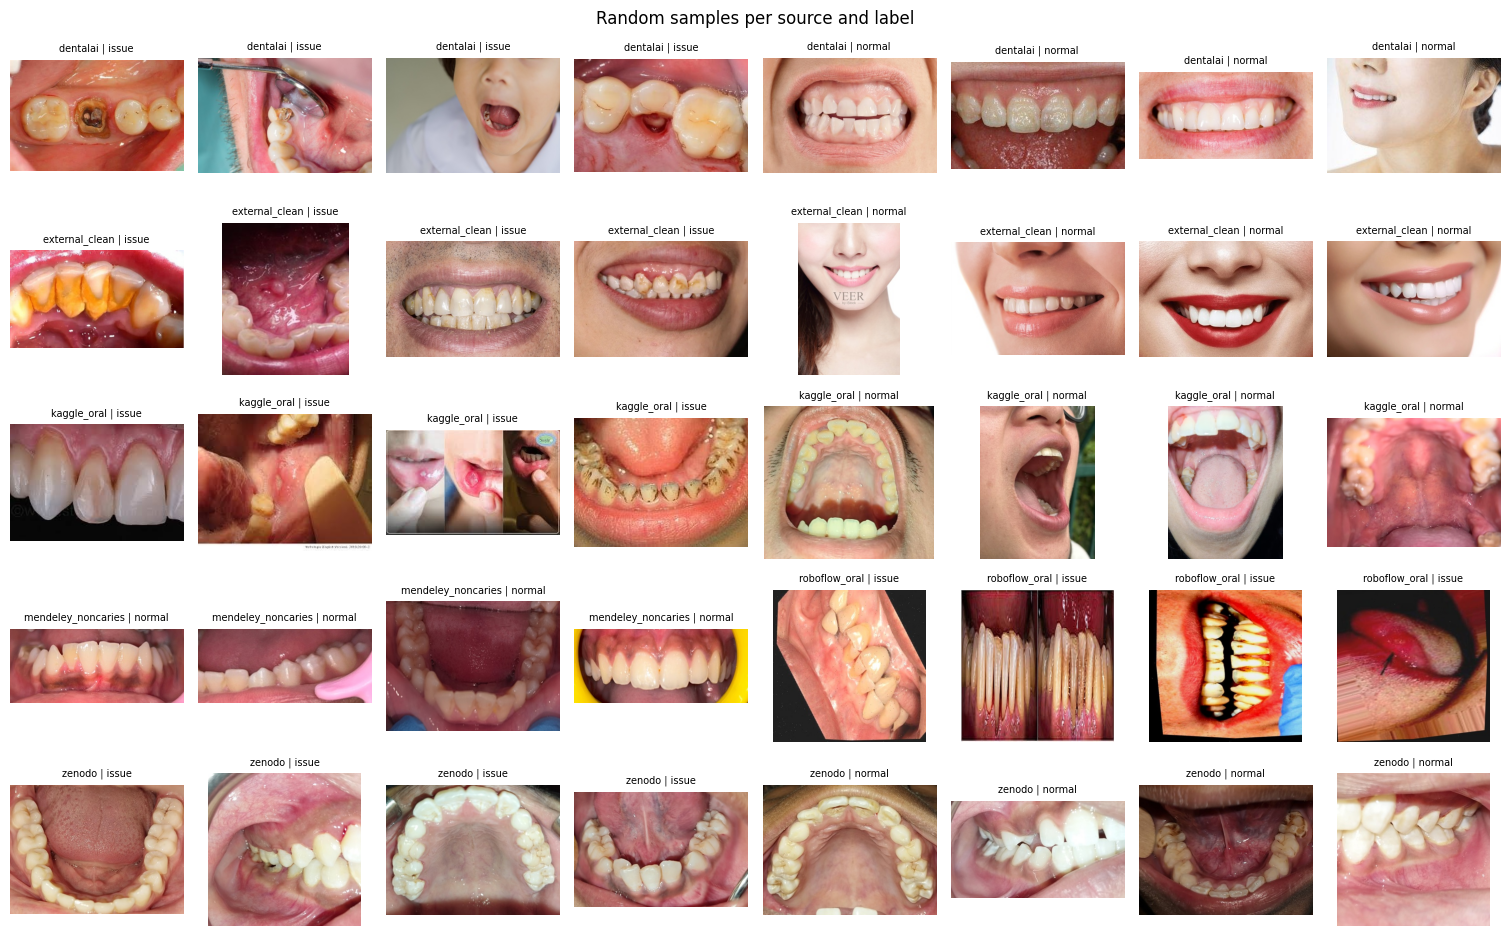

In [44]:
def show_grid(paths, titles=None, ncol=8, size=2.0, suptitle=None):
    n = len(paths); nrow = max(1, math.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size))
    for i, a in enumerate(np.atleast_1d(axes).flat):
        a.axis("off")
        if i < n:
            a.imshow(Image.open(paths[i]).convert("RGB"))
            if titles is not None: a.set_title(titles[i], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()


samp = df.groupby("stratum").sample(n=4, random_state=0)
show_grid(samp.cache.tolist(), samp.stratum.tolist(), ncol=8, size=1.9, suptitle="Random samples per source and label")

## 3. Splits: the dataset's split plus cross-source check sets

- **train / val / test** come from the dataset unchanged, so the classifier and YOLO are scored on the same images. The dataset already keeps every copy of a photo (Roboflow augmentations, re-uploads) in one split.
- **Cross-source check sets.** Val/test cannot tell "detects disease" from "detects Roboflow", so two extra sets are carved out of the **non-Roboflow training images**, by photo group and stratified by source × label (about 1/8 of those groups each):
  - `xsrc_val` is used for model selection and for the operating threshold, alongside val;
  - `xsrc_test` is used once, at the end, like test.

  These images are removed from the classifier's training set only. YOLO's `yolo_train.txt` is not affected.
- The assignment is saved to `manifests/Daniel/binary_classifier_split.csv` (image path, md5, group and role), so it can be rebuilt without sharing images.

In [45]:
ROLES = ["train", "val", "test", "xsrc_val", "xsrc_test"]


def carve_check_sets(df, frac, seed):
    # Two disjoint photo-group folds of the non-Roboflow training images, stratified by source x label.
    pool = df[(df.split == "train") & ~df.roboflow]
    k = round(1 / frac)
    folds = [te for _, te in StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
             .split(pool, pool.dataset + "|" + pool.label, pool.group)]
    folds.sort(key=lambda f: abs(len(f) - len(pool) / k))   # folds can be uneven: take the two closest to 1/k
    role = df.split.copy()
    role.loc[pool.index[folds[0]]] = "xsrc_val"
    role.loc[pool.index[folds[1]]] = "xsrc_test"
    return role


df["role"] = carve_check_sets(df, CFG["xsrc_frac"], CFG["seed"])
assert df.groupby("group").role.nunique().max() == 1, "a photo group straddles roles"
assert not df[df.role.str.startswith("xsrc")].roboflow.any()

display(pd.crosstab(df.role, df.label).loc[ROLES].assign(photo_groups=df.groupby("role").group.nunique()))
xs = df[df.role.str.startswith("xsrc")]
display(pd.crosstab(xs.dataset, [xs.role, xs.label]))

man = df[["image", "md5", "group", "dataset", "label_by", "has_issue", "split", "role"]].copy()
man.insert(0, "dataset_dir", rel(DATA_DIR))
man.to_csv(MANIFESTS / "binary_classifier_split.csv", index=False)
print("wrote", MANIFESTS / "binary_classifier_split.csv", len(man), "rows")

label,issue,normal,photo_groups
role,,,
train,22081,3443,12119
val,2301,640,1269
test,2447,599,1269
xsrc_val,592,574,957
xsrc_test,592,574,1026


role               xsrc_test        xsrc_val       
label                  issue normal    issue normal
dataset                                            
dentalai                 187     92      188     92
external_clean            41      7       40      7
kaggle_oral               94     15       94     15
mendeley_noncaries         0    454        0    454
zenodo                   270      6      270      6

wrote C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\manifests\Daniel\binary_classifier_split.csv 33843 rows


## 4. Training setup

### Backbones compared

All models are torchvision ImageNet-pretrained classifiers whose final linear layer is replaced with a 2-way head (normal, issue), then fully fine-tuned. The default sweep covers the main design families at a range of sizes:

| Family | Default sweep | Also registered in `BACKBONES` |
|---|---|---|
| ConvNeXt (modern CNN) | Tiny (28M) | Small (50M), Base (89M) |
| EfficientNet | B0 (5M), V2-S (21M) | B3 (12M) |
| ResNet / RegNet | ResNet-50 (26M) | RegNetY-3.2GF (19M) |
| DenseNet | DenseNet-121 (8M) | DenseNet-169 (14M) |
| MobileNet | V3-Large (5M): the cheapest option for the app | |
| Vision transformers | Swin-T (28M) | ViT-B/16 (86M) |

The peak learning rate is set per family (AdamW): 1e-4 for ConvNeXt and Swin, 5e-5 for ViT, 3e-4 for EfficientNet/ResNet/RegNet/DenseNet and 5e-4 for MobileNet. These are common fine-tuning defaults for each family. Everything else is identical across runs.

### Training recipe

* **Input.** The whole image is resized to 224×224 (squash, no centre-crop) so lesions near the edge, such as ulcers on the lip, are not cut off.
* **Epochs.** Each epoch draws `CFG["epoch_samples"]` (12,000) training images, so both recipes and all backbones get the same number of steps. At most 15 epochs, early stopping with patience 4.
* **Augmentation (B).** Random resized crops (which also vary the aspect ratio), small rotations, flips, brightness/contrast jitter with a deliberately tiny hue jitter (colour is diagnostic for discoloration and calculus), Gaussian blur and JPEG re-compression to mimic poor phone photos.
* **Balancing (B).** `WeightedRandomSampler`: normal and issue are drawn equally often. Within the issue class, Roboflow and the other sources get half the draws each, so the model cannot learn "not Roboflow means normal" from sampling frequency. Within each of these, every *photo group* is equally likely, so 200 augmented copies of one Roboflow photo count as one photo.
* **Loss.** Cross-entropy with label smoothing 0.1 (B). Some labels come from Qwen and some Normal images may hide a small finding, so the model should not be pushed to 100% confidence.
* **Optimiser.** AdamW, weight decay 0.05, cosine decay with 1 warm-up epoch, bf16 autocast. Early stopping and checkpoint choice on the **validation score** (below).

### Experiments

| ID | Backbone | Sampler | Augmentation | Purpose |
|---|---|---|---|---|
| A | ConvNeXt-Tiny | uniform random | flip only | Naive baseline: what the source confound does unchecked |
| B | every backbone in `CFG["sweep"]` | class + source + photo balanced | strong | Backbone comparison under the full recipe |

**Selection rule (fixed before training).** The validation score is the **mean of three macro-F1 values** (threshold 0.5): clean val, a "phone-quality" copy of val (each image downscaled to 160 px, darkened, blurred or heavily JPEG-compressed), and `xsrc_val`. The third term is there because val alone rewards the source shortcut.
1. The run with the highest validation score is the reference.
2. Every run within **0.01** of it counts as tied.
3. Among tied runs, the one with the **lowest CPU latency** wins, because the app runs the model on a CPU server.

The test sets are used once, after selection.

In [46]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics, shared by every torchvision model
S = CFG["img_size"]

# head = attribute path of the final nn.Linear that is replaced; lr = AdamW peak learning rate for fine-tuning
BACKBONES = {
    "convnext_tiny":      dict(family="ConvNeXt",     head="classifier.2", lr=1e-4),
    "convnext_small":     dict(family="ConvNeXt",     head="classifier.2", lr=1e-4),
    "convnext_base":      dict(family="ConvNeXt",     head="classifier.2", lr=1e-4),
    "efficientnet_b0":    dict(family="EfficientNet", head="classifier.1", lr=3e-4),
    "efficientnet_b3":    dict(family="EfficientNet", head="classifier.1", lr=3e-4),
    "efficientnet_v2_s":  dict(family="EfficientNet", head="classifier.1", lr=3e-4),
    "resnet50":           dict(family="ResNet",       head="fc",           lr=3e-4),
    "regnet_y_3_2gf":     dict(family="RegNet",       head="fc",           lr=3e-4),
    "densenet121":        dict(family="DenseNet",     head="classifier",   lr=3e-4),
    "densenet169":        dict(family="DenseNet",     head="classifier",   lr=3e-4),
    "mobilenet_v3_large": dict(family="MobileNet",    head="classifier.3", lr=5e-4),
    "swin_t":             dict(family="Swin",         head="head",         lr=1e-4),
    "vit_b_16":           dict(family="ViT",          head="heads.head",   lr=5e-5),
}
assert set(CFG["sweep"]) | {CFG["ablation_backbone"]} <= set(BACKBONES), "unknown backbone in CFG"


def make_tf(kind):
    norm = [v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)]
    if kind == "eval":
        return v2.Compose([v2.ToImage(), v2.Resize((S, S), antialias=True), *norm])
    if kind == "light":
        return v2.Compose([v2.ToImage(), v2.Resize((S, S), antialias=True), v2.RandomHorizontalFlip(), *norm])
    return v2.Compose([
        v2.ToImage(),
        v2.RandomResizedCrop(S, scale=(0.5, 1.0), ratio=(0.5, 2.0), antialias=True),
        v2.RandomHorizontalFlip(),
        v2.RandomApply([v2.RandomRotation(15)], p=0.5),
        v2.RandomApply([v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.15, hue=0.02)], p=0.8),
        v2.RandomApply([v2.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.2),
        v2.RandomApply([v2.JPEG((30, 90))], p=0.3),
        *norm])


# The Dataset and the photo degradations live in classifier_data.py next to this notebook: DataLoader worker processes
# can import them from there (on Windows they cannot load classes or lambdas defined in a notebook).
import sys, importlib
NB_DIR = ROOT / "models" / "classifier" / "notebooks" / "Daniel"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))
import classifier_data
importlib.reload(classifier_data)                 # picks up edits to the .py file without restarting the kernel
from classifier_data import ImageDS, DEGRADATIONS, val_degrade_list


def loader(df, tf, sampler=None, degrade=None, bs=None, workers=None, persistent=False):
    # `workers` processes decode and augment images in parallel while the GPU trains. persistent=True keeps them alive
    # between epochs (starting a worker on Windows takes a few seconds).
    ds = ImageDS(df.cache.values, df.y.astype(int).tolist(), tf, degrade)
    bs = bs or (CFG["batch_size"] if sampler is not None else CFG["eval_batch_size"])
    workers = CFG["num_workers"] if workers is None else workers
    return torch.utils.data.DataLoader(ds, batch_size=bs, sampler=sampler, shuffle=False, num_workers=workers,
                                       pin_memory=DEVICE.type == "cuda", persistent_workers=persistent and workers > 0,
                                       prefetch_factor=4 if workers > 0 else None)


def train_sampler(df, balanced):
    # Draws CFG["epoch_samples"] images per epoch.
    # balanced: each class gets half the draws; within a class, each source stratum (Roboflow / other) gets an equal
    # share; within a stratum each photo group is equally likely; within a group each file is equally likely.
    n = CFG["epoch_samples"]
    if not balanced:
        return torch.utils.data.RandomSampler(range(len(df)), num_samples=n)
    t = pd.DataFrame({"cls": df.label.values, "group": df.group.values,
                      "stratum": (df.label + "|" + np.where(df.roboflow, "roboflow", "other")).values})
    copies = t.groupby(["stratum", "group"]).group.transform("size")
    groups_in_stratum = t.groupby("stratum").group.transform("nunique")
    strata_in_class = t.groupby("cls").stratum.transform("nunique")
    w = 1.0 / (copies * groups_in_stratum * strata_in_class)
    return torch.utils.data.WeightedRandomSampler(torch.tensor(w.values, dtype=torch.double), num_samples=n, replacement=True)


def set_head(model, path, n):
    # Replace the nn.Linear at `path` (e.g. "classifier.2", "fc", "heads.head") with a fresh n-way layer.
    parent_path, _, attr = path.rpartition(".")
    parent = model.get_submodule(parent_path) if parent_path else model
    old = parent[int(attr)] if attr.isdigit() else getattr(parent, attr)
    new = nn.Linear(old.in_features, n)
    if attr.isdigit():
        parent[int(attr)] = new
    else:
        setattr(parent, attr, new)


def build_model(name, n=NUM_CLASSES, pretrained=True):
    m = tv.models.get_model(name, weights="DEFAULT" if pretrained else None)
    set_head(m, BACKBONES[name]["head"], n)
    return m


def cam_layer(model):
    # Layer whose activations Grad-CAM uses (the last spatial feature map of each architecture).
    if hasattr(model, "layer4"): return model.layer4               # ResNet
    if hasattr(model, "trunk_output"): return model.trunk_output   # RegNet
    if hasattr(model, "permute"): return model.permute             # Swin: (B, C, H, W) after the final permute
    if hasattr(model, "encoder"): return model.encoder.layers[-1]  # ViT: (B, 1 + N, D) tokens
    if hasattr(model.features, "denseblock4"): return model.features.denseblock4   # DenseNet (norm5 is ReLU'd in place)
    return model.features[-1]                                      # ConvNeXt, EfficientNet, MobileNet


def n_params_m(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


def cpu_latency_ms(model, reps=20):
    # Single-image fp32 latency on this machine's CPU: what the app server pays per upload. Leaves the model on CPU.
    m = model.float().cpu().eval(); x = torch.randn(1, 3, S, S)
    with torch.inference_mode():
        for _ in range(3): m(x)
        t0 = time.perf_counter()
        for _ in range(reps): m(x)
    return 1000 * (time.perf_counter() - t0) / reps


@torch.no_grad()
def predict_logits(model, dl):
    model.eval(); out, ys = [], []
    for x, y in dl:
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
            out.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys).numpy()


def p_issue(logits, T=1.0):
    return (logits.float() / T).softmax(1)[:, ISSUE].numpy()


def bin_metrics(y, logits, thr=0.5, T=1.0):
    # Binary metrics with "issue" as the positive class. Rank metrics (AUROC, AP) are NaN when only one class is present.
    y = np.asarray(y).astype(int); p = p_issue(logits, T); pred = (p >= thr).astype(int)
    both = len(np.unique(y)) == 2
    pos, neg = y == 1, y == 0
    sens = float((pred[pos] == 1).mean()) if pos.any() else np.nan
    spec = float((pred[neg] == 0).mean()) if neg.any() else np.nan
    return dict(acc=float(accuracy_score(y, pred)), bal_acc=float(np.nanmean([sens, spec])),
                macro_f1=float(f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0)) if both else np.nan,
                sensitivity=sens, specificity=spec,
                auroc=float(roc_auc_score(y, p)) if both else np.nan,
                ap=float(average_precision_score(y, p)) if both else np.nan)

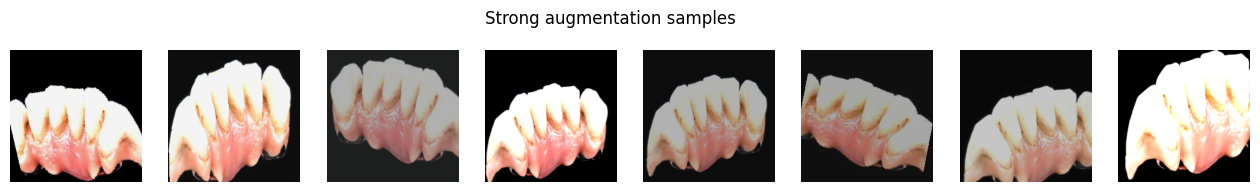

In [47]:
# Quick check of the augmentation pipeline: one non-Roboflow issue image under the strong transform
tf_s = make_tf("strong")
ex_path = df[(df.role == "train") & ~df.roboflow & (df.y == 1)].cache.iloc[0]
imgs = [tf_s(Image.open(ex_path).convert("RGB")) for _ in range(8)]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.2))
for a, t in zip(axes, imgs):
    a.imshow((t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)); a.axis("off")
fig.suptitle("Strong augmentation samples"); plt.show()

In [48]:
RECIPES = {
    "baseline":     dict(aug="light",  balanced=False, label_smoothing=0.0),   # A
    "balanced_aug": dict(aug="strong", balanced=True,  label_smoothing=0.1),   # B
}


def val_loader(val_df, xval_df):
    # One loader for the three selection sets (clean val, its phone-quality copy, xsrc_val), so its workers start once
    # per run and are reused every epoch. Returns (loader, number of val images).
    d = pd.concat([val_df, val_df, xval_df])
    degrade = [None] * len(val_df) + val_degrade_list(len(val_df)) + [None] * len(xval_df)
    return loader(d, make_tf("eval"), degrade=degrade, workers=CFG["eval_workers"], persistent=True), len(val_df)


def val_scores(model, vl):
    # Selection metrics: clean val, phone-quality val and cross-source val (all at threshold 0.5).
    dl, n = vl
    lg, y = predict_logits(model, dl)
    lv, yv, ld, lx, yx = lg[:n], y[:n], lg[n:2 * n], lg[2 * n:], y[2 * n:]
    m = {f"val_{k}": v for k, v in bin_metrics(yv, lv).items()}
    m.update({f"xval_{k}": v for k, v in bin_metrics(yx, lx).items()})
    m["val_degraded_macro_f1"] = bin_metrics(yv, ld)["macro_f1"]
    m["val_loss"] = F.cross_entropy(lv, torch.tensor(yv)).item()
    m["val_score"] = (m["val_macro_f1"] + m["val_degraded_macro_f1"] + m["xval_macro_f1"]) / 3
    return m


def train_experiment(name, backbone, recipe, train_df, val_df, xval_df):
    r = RECIPES[recipe]
    seed_everything()
    model = build_model(backbone).to(DEVICE)
    dl_tr = loader(train_df, make_tf(r["aug"]), sampler=train_sampler(train_df, r["balanced"]), persistent=True)
    vl = val_loader(val_df, xval_df)
    opt = torch.optim.AdamW(model.parameters(), lr=BACKBONES[backbone]["lr"], weight_decay=CFG["weight_decay"])
    steps = CFG["epochs"] * len(dl_tr); warm = CFG["warmup_epochs"] * len(dl_tr)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=r["label_smoothing"])
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)   # only needed for fp16

    best, best_state, hist, bad = -1, None, [], 0
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
                loss = crit(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        mv = val_scores(model, vl)
        hist.append(dict(epoch=ep, train_loss=tot / n, **mv, secs=time.time() - t0))
        print(f"{name} ep{ep:02d} train_loss {tot/n:.3f} | val f1 {mv['val_macro_f1']:.3f} degraded {mv['val_degraded_macro_f1']:.3f} "
              f"sens {mv['val_sensitivity']:.2f} spec {mv['val_specificity']:.2f} | xsrc_val f1 {mv['xval_macro_f1']:.3f} "
              f"auroc {mv['xval_auroc']:.3f} | score {mv['val_score']:.3f} ({time.time()-t0:.0f}s)")
        if mv["val_score"] > best:
            best, bad = mv["val_score"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print("early stop"); break
    model.load_state_dict(best_state)
    torch.save({"state_dict": best_state, "backbone": backbone, "head": BACKBONES[backbone]["head"], "classes": CLASSES},
               WEIGHTS / f"exp_{name}.pt")
    h = pd.DataFrame(hist)
    return h, summarize_run(name, backbone, recipe, model, vl, h)


def summarize_run(name, backbone, recipe, model, vl, h):
    # Validation metrics + size/speed of a trained model. `h` is its training history (may be empty).
    m = val_scores(model.to(DEVICE).eval(), vl)
    summary = dict(experiment=name, backbone=backbone, family=BACKBONES[backbone]["family"], recipe=recipe,
                   best_epoch=int(h.val_score.idxmax()) + 1 if len(h) else np.nan, epochs_run=len(h),
                   train_min=h.secs.sum() / 60 if len(h) else np.nan,
                   params_m=n_params_m(model), cpu_ms=cpu_latency_ms(model), **m)
    torch.cuda.empty_cache()
    return summary


def run_fingerprint(backbone, recipe, train_df, val_df, xval_df):
    # Identifies a run by its data split and settings, so a finished run is only reused when nothing relevant changed.
    # Only used to warn when a reused run was trained under different settings; it never triggers retraining.
    key = dict(backbone=backbone, recipe=RECIPES[recipe], lr=BACKBONES[backbone]["lr"],
               train=sorted(train_df.md5), val=sorted(val_df.md5), xval=sorted(xval_df.md5),
               **{k: CFG[k] for k in ["seed", "img_size", "epochs", "patience", "epoch_samples", "batch_size",
                                      "weight_decay", "warmup_epochs"]})
    return hashlib.md5(json.dumps(key, sort_keys=True).encode()).hexdigest()


def run_or_load(name, backbone, recipe, train_df, val_df, xval_df):
    # Trains a run only if it has no checkpoint yet (or is listed in CFG["retrain"]); otherwise reuses it.
    fp = run_fingerprint(backbone, recipe, train_df, val_df, xval_df)
    rec_path, ck_path = RUNS_DIR / f"{name}.json", WEIGHTS / f"exp_{name}.pt"
    force = CFG["retrain"] == "all" or name in CFG["retrain"]
    if ck_path.exists() and not force:
        if rec_path.exists():
            rec = json.loads(rec_path.read_text())
            if rec.get("fingerprint") not in (fp, "unknown"):
                print(f"  note: {name} was trained with a different split or settings than the current CFG "
                      f"(add it to CFG['retrain'] to retrain)")
            print(f"{name}: already trained, reusing (val score {rec['summary']['val_score']:.3f})")
            return pd.DataFrame(rec["history"]), rec["summary"]
        # Checkpoint but no record (e.g. the kernel stopped right after saving): rebuild the summary, don't retrain.
        print(f"{name}: checkpoint found without a run record; re-evaluating it on val instead of retraining")
        ck = torch.load(ck_path, map_location="cpu")
        assert ck["backbone"] == backbone, f"{ck_path.name} holds {ck['backbone']}, expected {backbone}"
        h, fp = pd.DataFrame(), "unknown"
        s = summarize_run(name, backbone, recipe, load_run_model(name), val_loader(val_df, xval_df), h)
    else:
        h, s = train_experiment(name, backbone, recipe, train_df, val_df, xval_df)
    rec_path.write_text(json.dumps(dict(fingerprint=fp, summary=s, history=h.to_dict("records")), indent=1, default=float))
    return h, s


def load_run_model(name):
    ck = torch.load(WEIGHTS / f"exp_{name}.pt", map_location="cpu")
    m = build_model(ck["backbone"], pretrained=False)
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval()

## 5. Train the experiments

Each run's best checkpoint is saved to `models/classifier/weights/Daniel/binary/exp_<name>.pt` and its training history to `models/classifier/results/Daniel/binary/runs/<name>.json`. **A run that already has a checkpoint is never retrained**: its saved results are reused, so re-running the notebook only trains backbones that are new in `CFG["sweep"]`, and an interrupted sweep resumes where it stopped. To retrain specific runs, list them in `CFG["retrain"]` (or set it to `"all"`). If the split or settings changed since a run was trained, a note is printed but the run is still reused.

Each epoch trains on 12,000 sampled images and evaluates on about 7,500 (val, its phone-quality copy and `xsrc_val`). `CFG["num_workers"]` worker processes prepare the images in parallel (code in `classifier_data.py`); the first epoch of each run waits a few seconds while they start. Trim `CFG["sweep"]` for a quicker run. The first run of each backbone also downloads its ImageNet weights.

In [49]:
sets = {r: df[df.role == r] for r in ROLES}
train_d, val_d, xval_d = sets["train"], sets["val"], sets["xsrc_val"]
print(" | ".join(f"{r} {len(d)}" for r, d in sets.items()))

EXPERIMENTS = {f"A_baseline_{CFG['ablation_backbone']}": dict(backbone=CFG["ablation_backbone"], recipe="baseline")}
EXPERIMENTS.update({f"B_{b}": dict(backbone=b, recipe="balanced_aug") for b in CFG["sweep"]})
print(f"{len(EXPERIMENTS)} runs:", ", ".join(EXPERIMENTS))

histories, summaries = {}, []
for name, kw in EXPERIMENTS.items():
    histories[name], s = run_or_load(name, train_df=train_d, val_df=val_d, xval_df=xval_d, **kw)
    summaries.append(s)
    torch.cuda.empty_cache()

train 25524 | val 2941 | test 3046 | xsrc_val 1166 | xsrc_test 1166
8 runs: A_baseline_convnext_tiny, B_convnext_tiny, B_efficientnet_b0, B_efficientnet_v2_s, B_resnet50, B_densenet121, B_mobilenet_v3_large, B_swin_t
A_baseline_convnext_tiny ep01 train_loss 0.148 | val f1 0.950 degraded 0.935 sens 0.99 spec 0.90 | xsrc_val f1 0.913 auroc 0.974 | score 0.933 (50s)
A_baseline_convnext_tiny ep02 train_loss 0.053 | val f1 0.958 degraded 0.949 sens 1.00 spec 0.88 | xsrc_val f1 0.942 auroc 0.984 | score 0.950 (21s)
A_baseline_convnext_tiny ep03 train_loss 0.039 | val f1 0.979 degraded 0.958 sens 1.00 spec 0.94 | xsrc_val f1 0.954 auroc 0.986 | score 0.963 (21s)
A_baseline_convnext_tiny ep04 train_loss 0.030 | val f1 0.964 degraded 0.913 sens 1.00 spec 0.89 | xsrc_val f1 0.931 auroc 0.980 | score 0.936 (22s)
A_baseline_convnext_tiny ep05 train_loss 0.036 | val f1 0.965 degraded 0.946 sens 1.00 spec 0.90 | xsrc_val f1 0.950 auroc 0.989 | score 0.954 (22s)
A_baseline_convnext_tiny ep06 train_lo

### 5.1 Comparison on validation

The table is sorted by the selection score. `params_m` is the parameter count in millions; `cpu_ms` is the single-image latency on this machine's CPU (fp32, batch 1). `xval_*` columns are on `xsrc_val`.

**`shortcut_gap`** = val macro-F1 − xsrc_val macro-F1. Val can be solved by recognising Roboflow images, `xsrc_val` cannot, so a large gap means the model is better at spotting the source than spotting disease. Read **A vs B on ConvNeXt-Tiny** first (does the recipe shrink the gap?), then the B rows against each other.

,family,params_m,cpu_ms,train_min,best_epoch,val_score,val_macro_f1,val_degraded_macro_f1,xval_macro_f1,shortcut_gap,val_sensitivity,val_specificity,xval_sensitivity,xval_specificity,xval_auroc
experiment,,,,,,,,,,,,,,,
B_efficientnet_b0,EfficientNet,4.010,11.052,5.886,10,0.971,0.980,0.977,0.957,0.023,0.999,0.942,0.965,0.949,0.975
B_convnext_tiny,ConvNeXt,27.822,24.791,5.992,12,0.971,0.980,0.974,0.961,0.019,0.999,0.941,0.973,0.948,0.981
B_swin_t,Swin,27.521,32.575,7.556,15,0.970,0.978,0.971,0.961,0.017,0.996,0.947,0.976,0.946,0.980
B_resnet50,ResNet,23.512,21.472,5.673,10,0.968,0.978,0.969,0.957,0.020,0.999,0.936,0.971,0.943,0.982
B_densenet121,DenseNet,6.956,24.147,8.515,13,0.967,0.974,0.971,0.957,0.017,0.996,0.936,0.973,0.941,0.981
B_mobilenet_v3_large,MobileNet,4.205,8.274,5.089,12,0.967,0.978,0.969,0.955,0.022,0.999,0.934,0.971,0.939,0.984
B_efficientnet_v2_s,EfficientNet,20.180,27.747,4.053,2,0.963,0.973,0.966,0.952,0.021,0.988,0.956,0.954,0.949,0.983
A_baseline_convnext_tiny,ConvNeXt,27.822,27.327,2.931,3,0.963,0.979,0.958,0.954,0.025,1.000,0.936,0.973,0.934,0.986


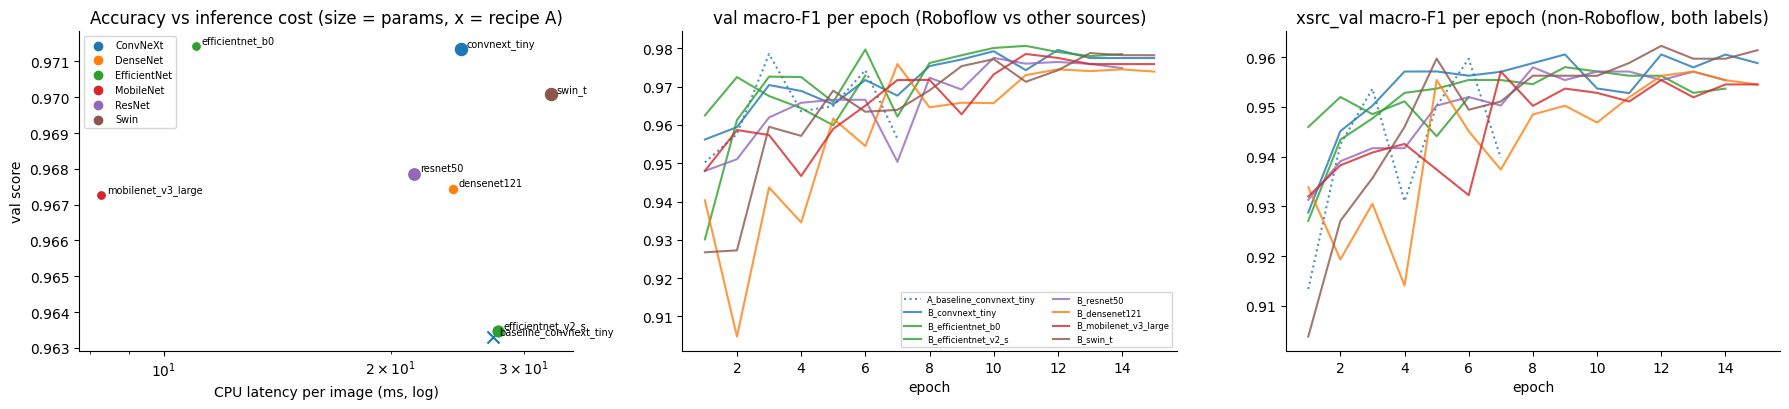

In [50]:
comp = pd.DataFrame(summaries).set_index("experiment")
comp["shortcut_gap"] = comp.val_macro_f1 - comp.xval_macro_f1
cols = ["family", "params_m", "cpu_ms", "train_min", "best_epoch", "val_score", "val_macro_f1", "val_degraded_macro_f1",
        "xval_macro_f1", "shortcut_gap", "val_sensitivity", "val_specificity", "xval_sensitivity", "xval_specificity", "xval_auroc"]
display(comp.sort_values("val_score", ascending=False)[cols].round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
fams = sorted(comp.family.unique()); colors = dict(zip(fams, plt.cm.tab10.colors))
for name, r in comp.iterrows():
    ax[0].scatter(r.cpu_ms, r.val_score, s=20 + 2 * r.params_m, color=colors[r.family],
                  marker="x" if r.recipe == "baseline" else "o")
    ax[0].annotate(name.split("_", 1)[1], (r.cpu_ms, r.val_score), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set(xlabel="CPU latency per image (ms, log)", ylabel="val score",
                                   title="Accuracy vs inference cost (size = params, x = recipe A)")
for f in fams: ax[0].scatter([], [], color=colors[f], label=f)
ax[0].legend(fontsize=7)
for name, h in histories.items():
    if h.empty: continue                      # re-evaluated checkpoint with no saved training history
    style = ":" if name.startswith("A_") else "-"
    c = colors[comp.loc[name, "family"]]
    ax[1].plot(h.epoch, h.val_macro_f1, style, color=c, alpha=0.8, label=name)
    ax[2].plot(h.epoch, h.xval_macro_f1, style, color=c, alpha=0.8)
ax[1].set(title="val macro-F1 per epoch (Roboflow vs other sources)", xlabel="epoch"); ax[1].legend(fontsize=6, ncol=2)
ax[2].set(title="xsrc_val macro-F1 per epoch (non-Roboflow, both labels)", xlabel="epoch")
plt.tight_layout(); plt.savefig(FIGS / "backbone_comparison.png", bbox_inches="tight"); plt.show()

In [51]:
# Selection rule (declared in section 4): best val score; within tie_margin of it, the fastest model on CPU wins
ranked = comp.sort_values("val_score", ascending=False)
top = ranked.val_score.iloc[0]
tied = ranked[ranked.val_score >= top - CFG["tie_margin"]]
BEST = tied.cpu_ms.idxmin()
BEST_BACKBONE = comp.loc[BEST, "backbone"]
print(f"best val score {top:.3f} ({ranked.index[0]}); runs within {CFG['tie_margin']}:")
display(tied[["params_m", "cpu_ms", "val_score"]].round(3))
print("selected experiment:", BEST, "| backbone:", BEST_BACKBONE)
model = load_run_model(BEST)

best val score 0.971 (B_efficientnet_b0); runs within 0.01:


,params_m,cpu_ms,val_score
experiment,,,
B_efficientnet_b0,4.010,11.052,0.971
B_convnext_tiny,27.822,24.791,0.971
B_swin_t,27.521,32.575,0.970
B_resnet50,23.512,21.472,0.968
B_densenet121,6.956,24.147,0.967
B_mobilenet_v3_large,4.205,8.274,0.967
B_efficientnet_v2_s,20.180,27.747,0.963
A_baseline_convnext_tiny,27.822,27.327,0.963


selected experiment: B_mobilenet_v3_large | backbone: mobilenet_v3_large


## 6. Evaluation on the held-out test sets

| Set | Images | What it measures |
|---|---|---|
| `test` | the dataset's test split, shared with YOLO | Issue images are all Roboflow and normal images all other sources, so this is an **upper bound**: a source detector would also score well |
| `test_person` | the test images whose labels were decided entirely by people (as in `data_person.yaml`) | Removes the Normal images Qwen judged; few normal images remain (only kaggle's Normal folder was filed by a person) |
| `xsrc_test` | the held-out non-Roboflow photos, both labels | The honest number for "detects a condition on photos from other cameras" (mostly caries vs normal) |

Metrics in this table use threshold 0.5; the operating threshold comes in 6.1. 95% confidence intervals for macro-F1 come from 1,000 bootstrap resamples of **photo groups** (all copies of one photo are drawn together, since they are not independent).

In [52]:
EVAL_SETS = ["test", "test_person", "xsrc_test"]
dls = {k: loader(sets[k], make_tf("eval")) for k in ["test", "xsrc_test"]}
test_logits = {}
for n in EXPERIMENTS:
    m = load_run_model(n); test_logits[n] = {k: predict_logits(m, d)[0] for k, d in dls.items()}
    del m; torch.cuda.empty_cache()


def eval_sets(lg):
    # {set name: (rows, logits)} for one run's test logits.
    te = sets["test"]; pm = te.label_by.eq("person").values
    return {"test": (te, lg["test"]), "test_person": (te[pm], lg["test"][torch.from_numpy(pm)]),
            "xsrc_test": (sets["xsrc_test"], lg["xsrc_test"])}


def group_bootstrap_ci(d, logits, thr=0.5, T=1.0, n=1000, seed=0):
    # 95% CI of macro-F1, resampling whole photo groups.
    y = d.y.values; pred = (p_issue(logits, T) >= thr).astype(int)
    codes = pd.factorize(d.group)[0]; order = np.argsort(codes, kind="stable")
    starts = np.r_[0, np.flatnonzero(np.diff(codes[order])) + 1]; idx = np.split(order, starts[1:])
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = np.concatenate([idx[g] for g in rng.integers(0, len(idx), len(idx))])
        vals.append(f1_score(y[i], pred[i], average="macro", labels=[0, 1], zero_division=0))
    return np.percentile(vals, [2.5, 97.5])


rows = []
for n, lg in test_logits.items():
    for s, (d, l) in eval_sets(lg).items():
        mt = bin_metrics(d.y.values, l); lo, hi = group_bootstrap_ci(d, l)
        rows.append(dict(experiment=n, set=s, images=len(d), macro_f1=mt["macro_f1"], macro_f1_95ci=f"[{lo:.3f}, {hi:.3f}]",
                         bal_acc=mt["bal_acc"], sensitivity=mt["sensitivity"], specificity=mt["specificity"], auroc=mt["auroc"]))
test_long = pd.DataFrame(rows)
test_table = test_long.drop(columns="images").set_index(["experiment", "set"]).unstack("set")
test_table.columns = [f"{s}_{m}" for m, s in test_table.columns]
print("images per test set:", test_long.drop_duplicates("set").set_index("set").images.to_dict())
show = [f"{s}_{m}" for s in EVAL_SETS for m in ["macro_f1", "macro_f1_95ci", "auroc"]]
display(comp[["family", "params_m", "cpu_ms", "val_score"]].join(test_table[show]).sort_values("val_score", ascending=False).round(3))
print("(All runs are shown for the comparison. Selection was made on validation only.)")

for s, (d, l) in eval_sets(test_logits[BEST]).items():
    print(f"\nSelected model {BEST}, {s} (threshold 0.5):")
    print(classification_report(d.y.values, (p_issue(l) >= 0.5).astype(int), labels=[0, 1], target_names=CLASSES,
                                digits=3, zero_division=0))

images per test set: {'test': 3046, 'test_person': 2507, 'xsrc_test': 1166}


,family,params_m,cpu_ms,val_score,test_macro_f1,test_macro_f1_95ci,test_auroc,test_person_macro_f1,test_person_macro_f1_95ci,test_person_auroc,xsrc_test_macro_f1,xsrc_test_macro_f1_95ci,xsrc_test_auroc
experiment,,,,,,,,,,,,,
B_efficientnet_b0,EfficientNet,4.010,11.052,0.971,0.980,"[0.973, 0.986]",0.990,0.917,"[0.874, 0.950]",0.953,0.944,"[0.930, 0.958]",0.970
B_convnext_tiny,ConvNeXt,27.822,24.791,0.971,0.977,"[0.970, 0.984]",0.995,0.919,"[0.877, 0.954]",0.980,0.954,"[0.941, 0.965]",0.978
B_swin_t,Swin,27.521,32.575,0.970,0.976,"[0.968, 0.983]",0.996,0.891,"[0.841, 0.930]",0.979,0.941,"[0.927, 0.954]",0.976
B_resnet50,ResNet,23.512,21.472,0.968,0.977,"[0.969, 0.984]",0.993,0.887,"[0.826, 0.940]",0.980,0.942,"[0.929, 0.955]",0.974
B_densenet121,DenseNet,6.956,24.147,0.967,0.975,"[0.968, 0.982]",0.990,0.880,"[0.829, 0.920]",0.967,0.944,"[0.931, 0.957]",0.974
B_mobilenet_v3_large,MobileNet,4.205,8.274,0.967,0.975,"[0.967, 0.982]",0.987,0.885,"[0.830, 0.931]",0.902,0.950,"[0.936, 0.963]",0.980
B_efficientnet_v2_s,EfficientNet,20.180,27.747,0.963,0.972,"[0.963, 0.981]",0.995,0.856,"[0.806, 0.903]",0.971,0.939,"[0.925, 0.953]",0.982
A_baseline_convnext_tiny,ConvNeXt,27.822,27.327,0.963,0.977,"[0.969, 0.984]",0.999,0.924,"[0.886, 0.960]",0.996,0.944,"[0.930, 0.957]",0.986


(All runs are shown for the comparison. Selection was made on validation only.)

Selected model B_mobilenet_v3_large, test (threshold 0.5):
              precision    recall  f1-score   support

      normal      0.981     0.940     0.960       599
       issue      0.985     0.996     0.990      2447

    accuracy                          0.985      3046
   macro avg      0.983     0.968     0.975      3046
weighted avg      0.985     0.985     0.984      3046


Selected model B_mobilenet_v3_large, test_person (threshold 0.5):
              precision    recall  f1-score   support

      normal      0.804     0.750     0.776        60
       issue      0.994     0.996     0.995      2447

    accuracy                          0.990      2507
   macro avg      0.899     0.873     0.885      2507
weighted avg      0.989     0.990     0.989      2507


Selected model B_mobilenet_v3_large, xsrc_test (threshold 0.5):
              precision    recall  f1-score   support

      normal      0

### 6.1 Calibration and operating threshold

The pipeline needs one yes/no decision: *send the photo to YOLO and recommend a dental check, or not*. A normal result skips YOLO, so a missed condition is silent, while an unnecessary flag only costs a YOLO run and a check-up. The threshold is therefore chosen for **sensitivity**: the highest threshold on calibrated P(issue) that still reaches 95% sensitivity on **both** val and `xsrc_val` (val alone would set it for Roboflow photos only).

A single **temperature**, fitted on the logits of val + `xsrc_val`, makes the probabilities interpretable ("70%" should mean roughly 70%) without changing the ranking. Expected calibration error (ECE) is measured on the test sets.

temperature T = 0.666
threshold for 95% sensitivity: val 0.981, xsrc_val 0.847 -> using 0.847

Selected model at the operating threshold 0.847:


,ECE_raw,ECE_calibrated,sensitivity,specificity,bal_acc,macro_f1
set,,,,,,
test,0.047,0.008,0.989,0.957,0.973,0.972
test_person,0.051,0.014,0.989,0.817,0.903,0.856
xsrc_test,0.037,0.027,0.936,0.958,0.947,0.947


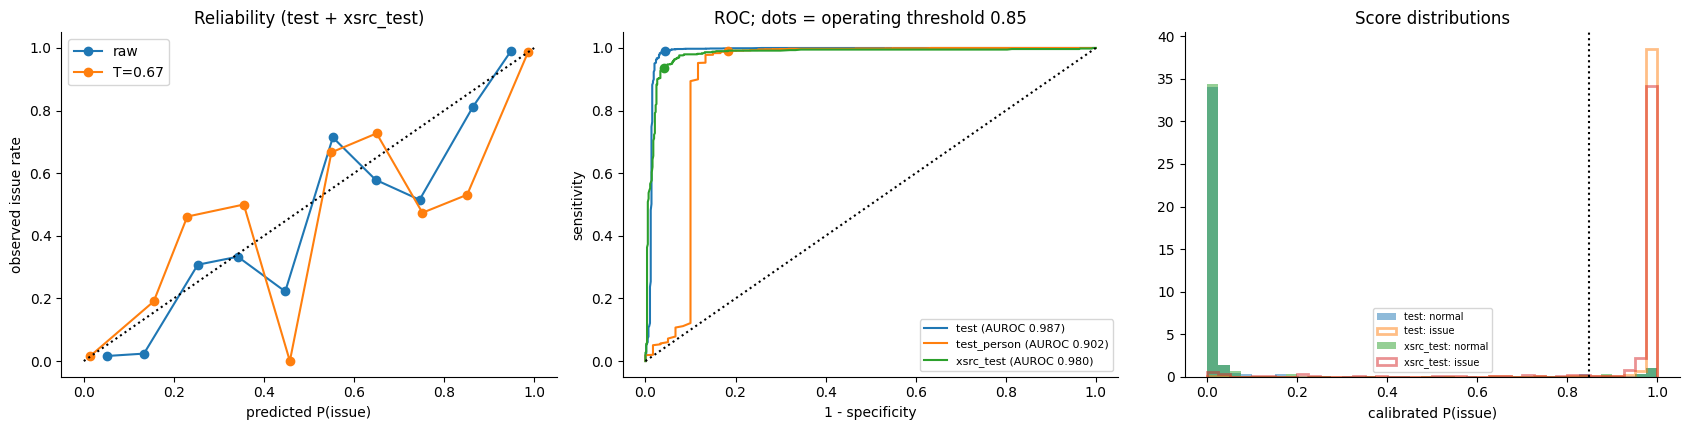

In [53]:
val_lg = {k: predict_logits(model, loader(sets[k], make_tf("eval")))[0] for k in ["val", "xsrc_val"]}


def fit_temperature(logits, y):
    t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([t], lr=0.1, max_iter=200)
    yt = torch.tensor(y)
    def closure():
        opt.zero_grad(); l = F.cross_entropy(logits / t.exp(), yt); l.backward(); return l
    opt.step(closure)
    return float(t.exp())


def ece_binary(p, y, bins=15):
    # Expected calibration error of P(issue): |observed issue rate - mean predicted| per bin, weighted by bin size.
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p > lo) & (p <= hi) if lo > 0 else (p >= lo) & (p <= hi)
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e


def thr_for_sensitivity(y, p, target):
    # Highest threshold t such that at least `target` of the issue images have p >= t.
    pos = np.sort(p[y == 1])
    return float(pos[int(np.floor((1 - target) * len(pos)))])


T = fit_temperature(torch.cat([val_lg["val"], val_lg["xsrc_val"]]),
                    np.concatenate([sets["val"].y.values, sets["xsrc_val"].y.values]))
thr_by_set = {k: thr_for_sensitivity(sets[k].y.values, p_issue(val_lg[k], T), CFG["target_sensitivity"]) for k in val_lg}
THRESH = min(thr_by_set.values())
print(f"temperature T = {T:.3f}")
print(f"threshold for {CFG['target_sensitivity']:.0%} sensitivity: " + ", ".join(f"{k} {v:.3f}" for k, v in thr_by_set.items())
      + f" -> using {THRESH:.3f}")

best_sets = eval_sets(test_logits[BEST])
op = []
for s, (d, l) in best_sets.items():
    mt = bin_metrics(d.y.values, l, thr=THRESH, T=T)
    op.append(dict(set=s, ECE_raw=ece_binary(p_issue(l), d.y.values), ECE_calibrated=ece_binary(p_issue(l, T), d.y.values),
                   **{k: mt[k] for k in ["sensitivity", "specificity", "bal_acc", "macro_f1"]}))
op_table = pd.DataFrame(op).set_index("set")
print(f"\nSelected model at the operating threshold {THRESH:.3f}:")
display(op_table.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
y_all = np.concatenate([best_sets[s][0].y.values for s in ["test", "xsrc_test"]])
lg_all = torch.cat([best_sets[s][1] for s in ["test", "xsrc_test"]])
for t_, lab in [(1.0, "raw"), (T, f"T={T:.2f}")]:
    p = p_issue(lg_all, t_); edges = np.linspace(0, 1, 11); xs_, ys_ = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p <= hi)
        if m.sum() >= 5: xs_.append(p[m].mean()); ys_.append(y_all[m].mean())
    ax[0].plot(xs_, ys_, "o-", label=lab)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="predicted P(issue)", ylabel="observed issue rate",
                                            title="Reliability (test + xsrc_test)"); ax[0].legend()
for s, (d, l) in best_sets.items():
    p = p_issue(l, T); fpr, tpr, _ = roc_curve(d.y.values, p)
    sens_, spec_ = op_table.loc[s, "sensitivity"], op_table.loc[s, "specificity"]
    line, = ax[1].plot(fpr, tpr, label=f"{s} (AUROC {roc_auc_score(d.y.values, p):.3f})")
    ax[1].plot(1 - spec_, sens_, "o", color=line.get_color())
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set(xlabel="1 - specificity", ylabel="sensitivity",
                                            title=f"ROC; dots = operating threshold {THRESH:.2f}"); ax[1].legend(fontsize=8)
for s in ["test", "xsrc_test"]:
    d, l = best_sets[s]; p = p_issue(l, T)
    ax[2].hist(p[d.y.values == 0], bins=40, range=(0, 1), alpha=0.5, label=f"{s}: normal", density=True)
    ax[2].hist(p[d.y.values == 1], bins=40, range=(0, 1), alpha=0.5, label=f"{s}: issue", density=True, histtype="step", lw=2)
ax[2].axvline(THRESH, c="k", ls=":"); ax[2].set(xlabel="calibrated P(issue)", title="Score distributions"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "calibration_threshold.png", bbox_inches="tight"); plt.show()

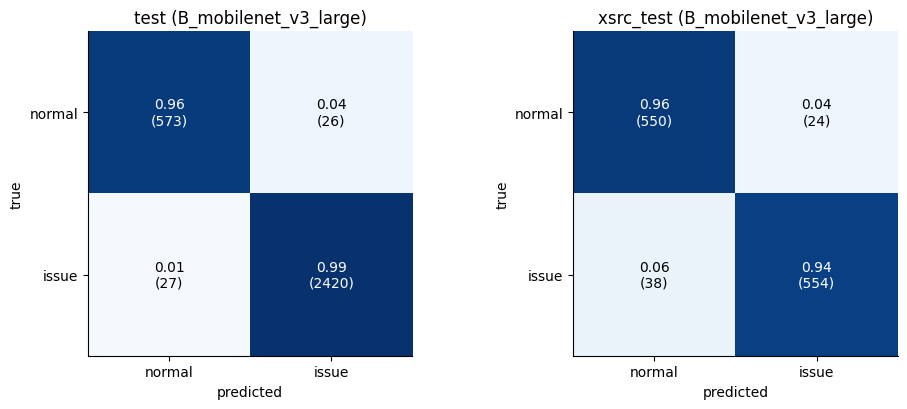

Per source at threshold 0.847. AUROC within a source is only defined where it has both labels:


images  issue  normal  sensitivity  specificity  auroc
set       dataset                                                                   
test      dentalai                92      0      92          NaN        0.859    NaN
          external_clean           6      0       6          NaN        1.000    NaN
          kaggle_oral             60      0      60          NaN        0.817    NaN
          mendeley_noncaries     435      0     435          NaN        1.000    NaN
          roboflow_oral         2447   2447       0        0.989          NaN    NaN
          zenodo                   6      0       6          NaN        0.667    NaN
xsrc_test dentalai               279    187      92        0.904        0.783  0.903
          external_clean          48     41       7        0.878        1.000  0.969
          kaggle_oral            109     94      15        0.915        0.933  0.962
          mendeley_noncaries     454      0     454          NaN        1.000    NaN
          zenodo                 276    270       6        0.974        0.500  0.846

In [54]:
# Confusion matrices at the operating threshold, and results per source (where a shortcut would show up)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, s in zip(ax, ["test", "xsrc_test"]):
    d, l = best_sets[s]; pred = (p_issue(l, T) >= THRESH).astype(int)
    cm = confusion_matrix(d.y.values, pred, labels=[0, 1]); cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
    a.set_xticks([0, 1], CLASSES); a.set_yticks([0, 1], CLASSES); a.set(xlabel="predicted", ylabel="true", title=f"{s} ({BEST})")
plt.tight_layout(); plt.savefig(FIGS / "confusion_matrix.png", bbox_inches="tight"); plt.show()

ps = []
for s in ["test", "xsrc_test"]:
    d, l = best_sets[s]; p = p_issue(l, T)
    for src in sorted(d.dataset.unique()):
        m = (d.dataset == src).values; y = d.y.values[m]; flag = p[m] >= THRESH
        ps.append(dict(set=s, dataset=src, images=int(m.sum()), issue=int(y.sum()), normal=int((y == 0).sum()),
                       sensitivity=flag[y == 1].mean() if (y == 1).any() else np.nan,
                       specificity=(~flag[y == 0]).mean() if (y == 0).any() else np.nan,
                       auroc=roc_auc_score(y, p[m]) if len(np.unique(y)) == 2 else np.nan))
per_src = pd.DataFrame(ps).set_index(["set", "dataset"])
print(f"Per source at threshold {THRESH:.3f}. AUROC within a source is only defined where it has both labels:")
display(per_src.round(3))

### 6.2 Robustness to poor photos

Patients will upload dark, blurry, low-resolution phone photos. The test sets are re-run under controlled degradations for the selected model and the A/B ablation pair (threshold 0.5, no recalibration). `changed` is the fraction of decisions that flip compared with the original photo.

In [55]:
rob_runs = [n for n in dict.fromkeys([BEST, f"A_baseline_{CFG['ablation_backbone']}", f"B_{CFG['ablation_backbone']}"]) if n in EXPERIMENTS]
rob_all = []
for n in rob_runs:
    m = load_run_model(n)
    for s in ["test", "xsrc_test"]:
        d = sets[s]; base = None
        for dname, fn in DEGRADATIONS.items():
            lg, _ = predict_logits(m, loader(d, make_tf("eval"), degrade=fn))
            mt = bin_metrics(d.y.values, lg); pr = p_issue(lg) >= 0.5; base = pr if base is None else base
            rob_all.append(dict(experiment=n, set=s, condition=dname, macro_f1=mt["macro_f1"], sensitivity=mt["sensitivity"],
                                specificity=mt["specificity"], changed=(pr != base).mean()))
    del m; torch.cuda.empty_cache()
rob_df = pd.DataFrame(rob_all)
for metric in ["macro_f1", "sensitivity", "specificity"]:
    print(f"{metric} under degraded photos")
    display(rob_df.pivot_table(index=["experiment", "set"], columns="condition", values=metric)[list(DEGRADATIONS)].round(3))
rob = rob_df[rob_df.experiment == BEST].drop(columns="experiment").to_dict("records")

macro_f1 under degraded photos


condition                           original  low-res 160px + JPEG60  dark (x0.5)  bright (x1.6)  blur (r=2)  JPEG q=20
experiment               set                                                                                           
A_baseline_convnext_tiny test          0.977                   0.952        0.970          0.945       0.952      0.944
                         xsrc_test     0.944                   0.908        0.934          0.922       0.838      0.925
B_convnext_tiny          test          0.977                   0.965        0.975          0.968       0.970      0.970
                         xsrc_test     0.954                   0.945        0.954          0.951       0.954      0.943
B_mobilenet_v3_large     test          0.975                   0.957        0.967          0.960       0.966      0.964
                         xsrc_test     0.950                   0.933        0.944          0.933       0.943      0.939

sensitivity under degraded photos


condition                           original  low-res 160px + JPEG60  dark (x0.5)  bright (x1.6)  blur (r=2)  JPEG q=20
experiment               set                                                                                           
A_baseline_convnext_tiny test          0.998                   0.989        0.989          1.000       0.969      0.998
                         xsrc_test     0.959                   0.904        0.927          0.986       0.716      0.973
B_convnext_tiny          test          0.998                   0.992        0.997          0.993       0.990      0.996
                         xsrc_test     0.963                   0.963        0.973          0.961       0.956      0.959
B_mobilenet_v3_large     test          0.996                   0.985        0.993          0.995       0.991      0.993
                         xsrc_test     0.965                   0.946        0.961          0.958       0.953      0.953

specificity under degraded photos


condition                           original  low-res 160px + JPEG60  dark (x0.5)  bright (x1.6)  blur (r=2)  JPEG q=20
experiment               set                                                                                           
A_baseline_convnext_tiny test          0.937                   0.896        0.948          0.836       0.965      0.840
                         xsrc_test     0.929                   0.913        0.941          0.857       0.969      0.876
B_convnext_tiny          test          0.938                   0.922        0.933          0.927       0.943      0.923
                         xsrc_test     0.944                   0.927        0.934          0.941       0.951      0.927
B_mobilenet_v3_large     test          0.940                   0.922        0.927          0.898       0.928      0.913
                         xsrc_test     0.936                   0.920        0.927          0.908       0.932      0.925

### 6.3 Explainability: Grad-CAM

Grad-CAM shows which pixels drove the **issue** score of the selected model. For this dataset the key check is whether the model looks at teeth, gums and lesions, or at image borders, background, lips or text (signs that it learned the source). For ViT the token grid is reshaped to a 14×14 map, so its maps are coarser than the CNNs'.

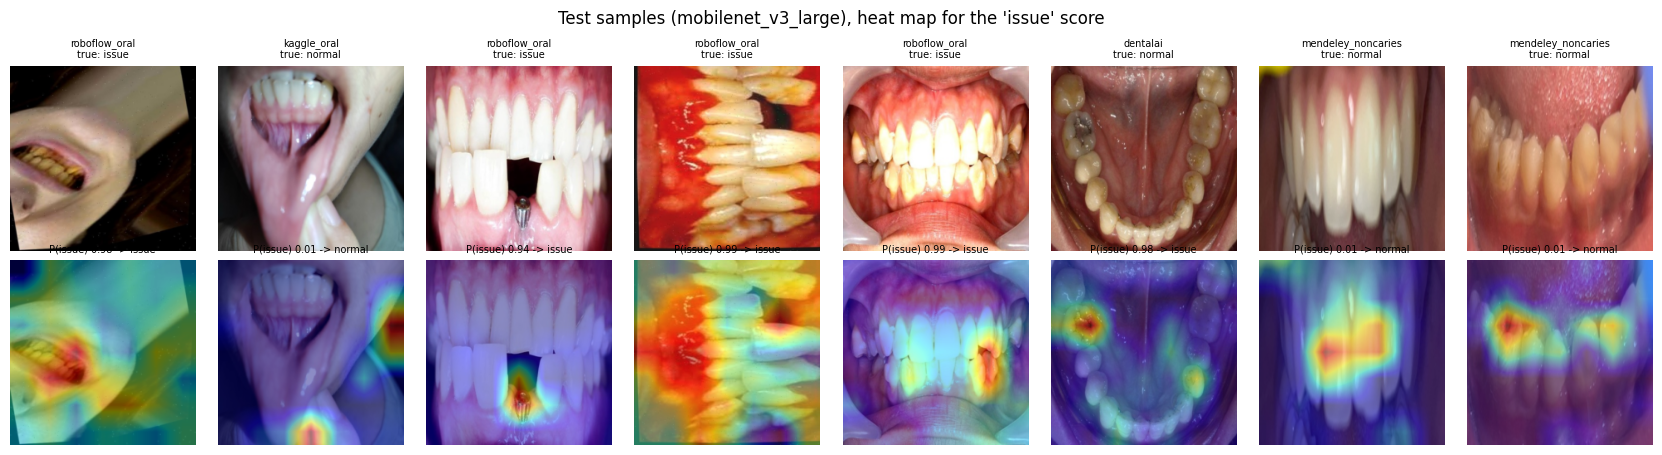

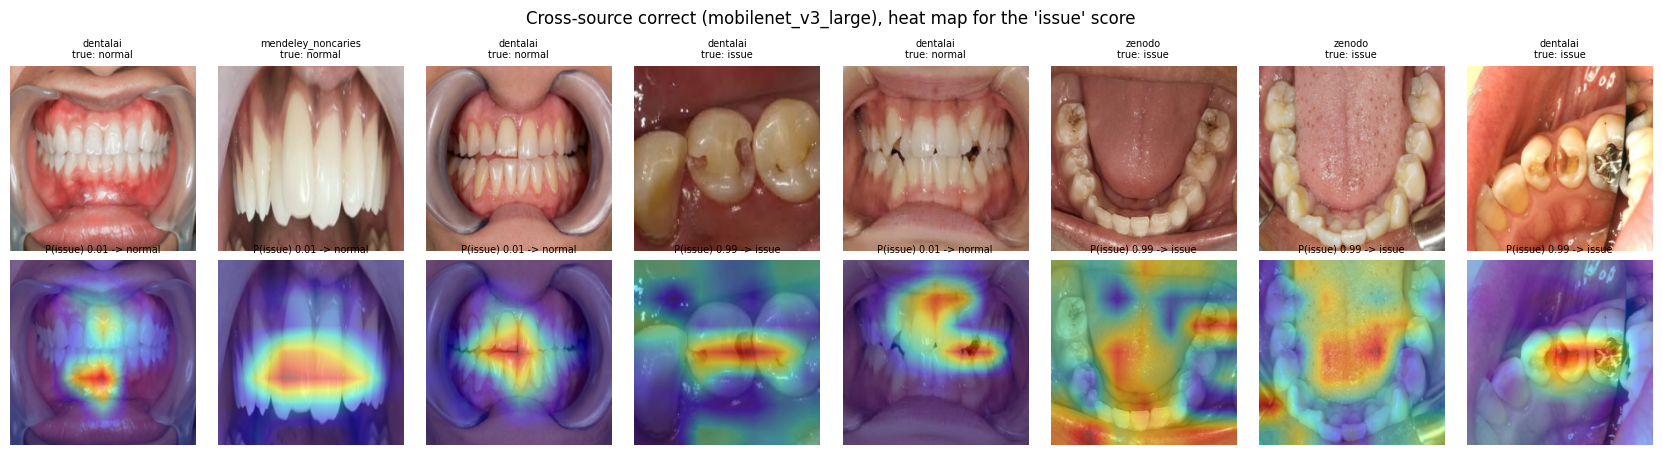

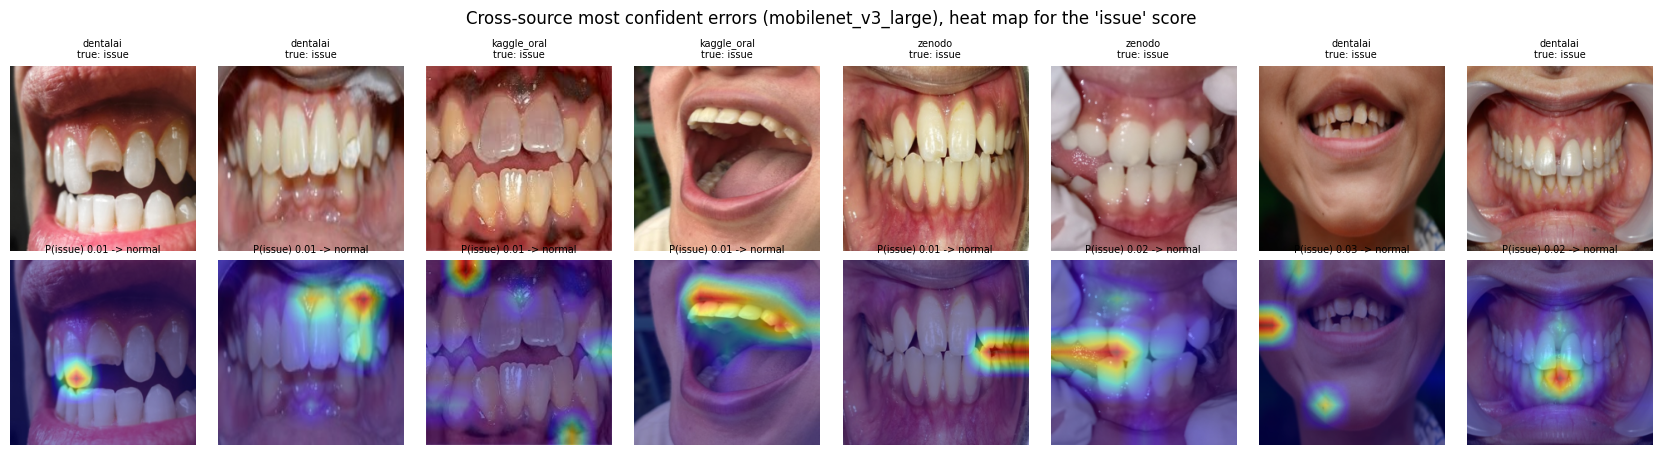

In [56]:
def _to_map(t):
    # CNN / Swin activations are already (B, C, H, W); ViT tokens (B, 1 + N, D) become (B, D, sqrt N, sqrt N).
    if t.ndim == 3:
        t = t[:, 1:, :]; s = int(round(t.shape[1] ** 0.5))
        t = t.reshape(t.shape[0], s, s, t.shape[2]).permute(0, 3, 1, 2)
    return t


def gradcam(model, x, cls):
    store = {}
    layer = cam_layer(model)
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    logits = model(x)
    logits[:, cls].sum().backward()
    h.remove()
    a, g = _to_map(store["a"]), _to_map(store["g"])
    w = g.mean((2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu(), logits.detach()


def show_cams(d, title, n=8):
    d = d.head(n)
    if not len(d): print(f"{title}: no images"); return
    x = torch.stack([make_tf("eval")(Image.open(p).convert("RGB")) for p in d.cache]).to(DEVICE)
    cams, logits = gradcam(model.float(), x, ISSUE)
    p = p_issue(logits.cpu(), T)
    fig, axes = plt.subplots(2, len(d), figsize=(2.1 * len(d), 4.6))
    axes = np.array(axes).reshape(2, -1)
    for i in range(len(d)):
        img = (x[i].cpu().permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()
        axes[0, i].imshow(img); axes[0, i].set_title(f"{d.dataset.iloc[i]}\ntrue: {d.label.iloc[i]}", fontsize=7)
        axes[1, i].imshow(img); axes[1, i].imshow(cams[i], cmap="jet", alpha=0.45)
        axes[1, i].set_title(f"P(issue) {p[i]:.2f} -> {CLASSES[int(p[i] >= THRESH)]}", fontsize=7)
        for a in axes[:, i]: a.axis("off")
    fig.suptitle(f"{title} ({BEST_BACKBONE}), heat map for the 'issue' score"); plt.tight_layout()
    plt.savefig(FIGS / f"gradcam_{title.lower().replace(' ', '_')}.png", bbox_inches="tight"); plt.show()


def with_preds(s):
    d, l = best_sets[s]; p = p_issue(l, T)
    return d.assign(p_issue=p, pred=np.array(CLASSES)[(p >= THRESH).astype(int)], margin=np.abs(p - THRESH))


te, xt = with_preds("test"), with_preds("xsrc_test")
show_cams(te.sample(frac=1, random_state=0).groupby("label").head(4), "Test samples")
show_cams(xt[xt.pred == xt.label].sample(frac=1, random_state=0).groupby("label").head(4), "Cross-source correct")
show_cams(xt[xt.pred != xt.label].sort_values("margin", ascending=False), "Cross-source most confident errors")

## 7. Save the model and results

The checkpoint goes to `models/classifier/weights/Daniel/binary/best.pt`. It holds the temperature and the operating threshold, so an app can reproduce `predict_image` below: **P(issue) ≥ threshold → run the YOLO detector and recommend a dental check**.

In [57]:
def predict_image(image_path, model=model, T=T, thresh=THRESH):
    # Stage 1 of the pipeline. has_issue=True -> send the photo to the YOLO detector and recommend a dental check.
    im = load_rgb(image_path, CFG["cache_max_side"])
    x = make_tf("eval")(im)[None].to(DEVICE)
    with torch.no_grad():
        p = float(p_issue(model.float().eval()(x).cpu(), T)[0])
    k = int(p >= thresh)
    return {"has_issue": bool(k), "p_issue": round(p, 4), "threshold": round(thresh, 4),
            "class_name": CLASSES[k], "display_name": DISPLAY[CLASSES[k]]}


for r in sets["test"].groupby(["dataset", "label"]).head(1).itertuples():
    out = predict_image(r.path)
    print(f"{r.dataset:>20} {r.label:>6} -> has_issue={out['has_issue']!s:<5} P(issue) {out['p_issue']:.3f}")

       roboflow_oral  issue -> has_issue=True  P(issue) 0.989
  mendeley_noncaries normal -> has_issue=False P(issue) 0.012
            dentalai normal -> has_issue=False P(issue) 0.013
         kaggle_oral normal -> has_issue=True  P(issue) 0.992
              zenodo normal -> has_issue=True  P(issue) 0.880
      external_clean normal -> has_issue=False P(issue) 0.014


In [58]:
def plain(x):
    # numpy scalars -> Python floats, so the checkpoint loads with torch.load(weights_only=True)
    return json.loads(json.dumps(x, default=float))


final_test = {s: bin_metrics(d.y.values, l, thr=THRESH, T=T) for s, (d, l) in best_sets.items()}
ckpt = dict(
    state_dict={k: v.cpu() for k, v in model.state_dict().items()},
    backbone=BEST_BACKBONE, head=BACKBONES[BEST_BACKBONE]["head"],
    task="binary", classes=CLASSES, class_ids=list(range(NUM_CLASSES)), positive_class=CLASSES[ISSUE],
    display_names=DISPLAY, conditions_screened=CONDITIONS,
    img_size=S, mean=MEAN, std=STD,
    preprocessing="EXIF-transpose, RGB, thumbnail to 384px, resize (squash) to 224x224, ImageNet normalise",
    temperature=T, threshold=THRESH, target_sensitivity=CFG["target_sensitivity"],
    experiment=BEST, config=plain(CFG), dataset=rel(DATA_DIR),
    val_metrics=plain(comp.loc[BEST].to_dict()), test_metrics=plain(final_test),
    created=datetime.datetime.now().isoformat(timespec="seconds"),
    notes=("Stage 1 (issue or not) of the classifier + YOLO pipeline. Screening and education aid only, not a diagnosis. "
           "Trained on non-Singapore photos. 'normal' means none of the 5 screened conditions was seen; it cannot detect "
           "gum disease. p_issue = softmax(logits / temperature)[1]; p_issue >= threshold -> run the YOLO detector and "
           "recommend a dental check."),
)
torch.save(ckpt, WEIGHTS / "best.pt")

comp.join(test_table).reset_index().assign(
    date=datetime.date.today().isoformat(), selected=lambda d: d.experiment == BEST
).to_csv(RESULTS / "experiments.csv", index=False)
json.dump(plain(dict(experiment=BEST, backbone=BEST_BACKBONE, temperature=T, threshold=THRESH,
                     target_sensitivity=CFG["target_sensitivity"],
                     test_at_threshold=final_test,
                     test_at_0_5={s: bin_metrics(d.y.values, l) for s, (d, l) in best_sets.items()},
                     macro_f1_95ci_at_0_5={s: test_table.loc[BEST, f"{s}_macro_f1_95ci"] for s in EVAL_SETS},
                     per_source=per_src.reset_index().to_dict("records"), robustness=rob,
                     images={r: int(len(d)) for r, d in sets.items()})),
          open(RESULTS / "test_metrics.json", "w"), indent=2)
print("saved:", WEIGHTS / "best.pt", "|", RESULTS / "experiments.csv", "|", RESULTS / "test_metrics.json", "|", FIGS)

saved: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\weights\Daniel\binary\best.pt | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\Daniel\binary\experiments.csv | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\Daniel\binary\test_metrics.json | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\Daniel\binary\figures


## 8. Results at a glance

The table below is generated from this run, so it always matches the saved files. Exact numbers vary slightly between runs (GPU non-determinism); `models/classifier/results/Daniel/binary/experiments.csv` and `test_metrics.json` hold the latest values.

**Questions the table answers for the report**
1. **Shortcut.** How far apart are `test` and `xsrc_test`? `test` can be solved by recognising Roboflow images; `xsrc_test` cannot. The gap is the best available estimate of how much the model relies on the source.
2. **Training recipe.** Does balancing by source + strong augmentation (B) improve `xsrc_test` and shrink the gap compared with the naive baseline (A) on ConvNeXt-Tiny?
3. **Architecture and size.** Do bigger or attention-based models help on photos from other sources, or only on val/test? Compare gains against the bootstrap CI width.
4. **Operating point.** At the 95%-sensitivity threshold, what specificity is left on `xsrc_test`, i.e. how many healthy mouths are sent on to YOLO and told to see a dentist?

In [59]:
glance = (comp[["family", "recipe", "params_m", "cpu_ms", "val_score", "shortcut_gap"]]
          .join(test_table[["test_macro_f1", "test_macro_f1_95ci", "xsrc_test_macro_f1", "xsrc_test_macro_f1_95ci",
                            "xsrc_test_auroc"]])
          .sort_values("val_score", ascending=False))
glance.insert(0, "selected", np.where(glance.index == BEST, "<<", ""))
display(glance.round(3))

a_name, b_name = f"A_baseline_{CFG['ablation_backbone']}", f"B_{CFG['ablation_backbone']}"
g = glance
lines = [f"- **Selected:** `{BEST}` ({comp.loc[BEST, 'params_m']:.0f}M params, {comp.loc[BEST, 'cpu_ms']:.0f} ms/image on CPU): "
         f"test macro-F1 {g.loc[BEST, 'test_macro_f1']:.3f} {g.loc[BEST, 'test_macro_f1_95ci']}, "
         f"xsrc_test macro-F1 {g.loc[BEST, 'xsrc_test_macro_f1']:.3f} {g.loc[BEST, 'xsrc_test_macro_f1_95ci']} (threshold 0.5)."]
if a_name in g.index and b_name in g.index:
    lines.append(f"- **Recipe (A to B on {CFG['ablation_backbone']}):** xsrc_test macro-F1 {g.loc[a_name, 'xsrc_test_macro_f1']:.3f} to "
                 f"{g.loc[b_name, 'xsrc_test_macro_f1']:.3f}; val shortcut gap {g.loc[a_name, 'shortcut_gap']:.3f} to "
                 f"{g.loc[b_name, 'shortcut_gap']:.3f}.")
b_runs = g[g.recipe == "balanced_aug"]
if len(b_runs):
    lines.append(f"- **Backbones (recipe B):** val score ranges from {b_runs.val_score.min():.3f} (`{b_runs.val_score.idxmin()}`) "
                 f"to {b_runs.val_score.max():.3f} (`{b_runs.val_score.idxmax()}`).")
    fastest = b_runs.cpu_ms.idxmin()
    lines.append(f"- **Cheapest model:** `{fastest}` ({b_runs.loc[fastest, 'cpu_ms']:.0f} ms/image), xsrc_test macro-F1 "
                 f"{b_runs.loc[fastest, 'xsrc_test_macro_f1']:.3f}.")
lines.append(f"- **Operating point:** threshold {THRESH:.2f} (temperature {T:.2f}) gives sensitivity / specificity of "
             + "; ".join(f"{s} {op_table.loc[s, 'sensitivity']:.2f} / {op_table.loc[s, 'specificity']:.2f}" for s in EVAL_SETS) + ".")
display(Markdown("\n".join(lines)))

,selected,family,recipe,params_m,cpu_ms,val_score,shortcut_gap,test_macro_f1,test_macro_f1_95ci,xsrc_test_macro_f1,xsrc_test_macro_f1_95ci,xsrc_test_auroc
experiment,,,,,,,,,,,,
B_efficientnet_b0,,EfficientNet,balanced_aug,4.010,11.052,0.971,0.023,0.980,"[0.973, 0.986]",0.944,"[0.930, 0.958]",0.970
B_convnext_tiny,,ConvNeXt,balanced_aug,27.822,24.791,0.971,0.019,0.977,"[0.970, 0.984]",0.954,"[0.941, 0.965]",0.978
B_swin_t,,Swin,balanced_aug,27.521,32.575,0.970,0.017,0.976,"[0.968, 0.983]",0.941,"[0.927, 0.954]",0.976
B_resnet50,,ResNet,balanced_aug,23.512,21.472,0.968,0.020,0.977,"[0.969, 0.984]",0.942,"[0.929, 0.955]",0.974
B_densenet121,,DenseNet,balanced_aug,6.956,24.147,0.967,0.017,0.975,"[0.968, 0.982]",0.944,"[0.931, 0.957]",0.974
B_mobilenet_v3_large,<<,MobileNet,balanced_aug,4.205,8.274,0.967,0.022,0.975,"[0.967, 0.982]",0.950,"[0.936, 0.963]",0.980
B_efficientnet_v2_s,,EfficientNet,balanced_aug,20.180,27.747,0.963,0.021,0.972,"[0.963, 0.981]",0.939,"[0.925, 0.953]",0.982
A_baseline_convnext_tiny,,ConvNeXt,baseline,27.822,27.327,0.963,0.025,0.977,"[0.969, 0.984]",0.944,"[0.930, 0.957]",0.986


- **Selected:** `B_mobilenet_v3_large` (4M params, 8 ms/image on CPU): test macro-F1 0.975 [0.967, 0.982], xsrc_test macro-F1 0.950 [0.936, 0.963] (threshold 0.5).
- **Recipe (A to B on convnext_tiny):** xsrc_test macro-F1 0.944 to 0.954; val shortcut gap 0.025 to 0.019.
- **Backbones (recipe B):** val score ranges from 0.963 (`B_efficientnet_v2_s`) to 0.971 (`B_efficientnet_b0`).
- **Cheapest model:** `B_mobilenet_v3_large` (8 ms/image), xsrc_test macro-F1 0.950.
- **Operating point:** threshold 0.85 (temperature 0.67) gives sensitivity / specificity of test 0.99 / 0.96; test_person 0.99 / 0.82; xsrc_test 0.94 / 0.96.

## 9. Limitations and responsible-AI notes (for the report)

**What the numbers do and do not show**
- **`test` is an upper bound.** Its two classes come from different sources, so it rewards a source detector. Always quote `xsrc_test` next to it; the gap between them is the size of the shortcut that this data allows.
- **`xsrc_test` is narrow.** Outside Roboflow, issue images are mostly caries (plus discoloration from zenodo), so it says little about ulcers, hypodontia or calculus on non-Roboflow photos. Those are only tested on Roboflow images.
- **Labels.** Most Normal images in val/test were judged Normal by Qwen, which may miss a small finding; such images would show up as false positives. `test_person` avoids this but has few normal images. In training, non-Roboflow issue labels mix people (caries in dentalai/zenodo) and Qwen.
- **Model comparison.** Every backbone was trained once, with one seed and one learning rate per family. Differences smaller than the bootstrap CI (or the 0.01 tie margin) should not be reported as one architecture being better.
- **No external validation.** All images come from public datasets and web sources. Real phone photos from patients, and early, subtle disease (the case the brief cares about most), are under-represented, so real-world sensitivity is likely **lower** than measured here.

**Dataset issues that cannot be fixed by modelling**
- **The source confound** can only be removed with data: normal and abnormal photos taken with the same cameras and settings (for example, a clinic photographing every patient, healthy or not).
- **No gum disease class.** Up to 90% of Singapore adults have some gum disease and the model cannot see it. The app must never say "your mouth is healthy". It should say "none of the five screened conditions was detected" and always prompt for a check-up, especially if gums bleed.
- **Not Singapore patients; no demographic metadata.** We cannot measure performance by age, ethnicity or gum pigmentation. Before real use, a Singapore validation set (for example through the Oral Link collaboration) with consented demographic fields is needed.
- **Hypodontia** (congenitally missing teeth) is a developmental condition, mostly photographed in children. A photo of an adult with an extracted tooth may be labelled hypodontia, so the app should phrase this as "gap / missing tooth".

**Safety, privacy and transparency in the app**
- A normal result skips the YOLO stage, so the classifier's false negatives are silent. This is why the threshold targets sensitivity, and why the app should still recommend routine check-ups after a normal result.
- Poor-quality photos (the `quality_check` model) should lead to a retake, never a guess.
- Emergency red flags (facial swelling, uncontrolled bleeding, trauma) must be screened *before* the classifier and routed to 995 / A&E, regardless of the model output.
- PDPA: classify in memory, do not retain uploaded photos without explicit consent, and never use them for retraining without separate consent.
- Grad-CAM overlays can be shown to the user ("the model looked here") to make the screening less of a black box.